In [1]:
from pathlib import Path
import geopandas as gpd
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import contextily as ctx
from shapely.geometry import Point, LineString
import colorcet as cc
from shapely.ops import substring
from shapely.geometry import MultiLineString
from matplotlib.ticker import AutoMinorLocator
from scipy.stats import linregress, theilslopes
import matplotlib.patheffects as pe
from matplotlib.collections import LineCollection
from matplotlib.lines import Line2D
from matplotlib.legend_handler import HandlerTuple
from matplotlib.transforms import blended_transform_factory
from matplotlib.ticker import MultipleLocator
from matplotlib.colors import ListedColormap, BoundaryNorm
from matplotlib.patches import Patch
from mpl_toolkits.axes_grid1.inset_locator import inset_axes
from scipy import stats
import io
import contextlib

figures = {}
tables = {}


## Load Data

In [56]:
SAVE = False   # True = save figures and tables in results/ (overwrites the files there)

data_folder = Path("../data")
fig_dir = Path("../results")
table_dir = Path("../results")

STAC_VERSION = "v2.1"

def load_data(data_folder):

    change_rate = gpd.read_parquet(
        data_folder / f"mekong_change_rate_{STAC_VERSION}.parquet"
    )

    shorelines = gpd.read_parquet(
        data_folder / f"mekong_shorelines_{STAC_VERSION}.parquet"
    )

    series = gpd.read_parquet(
        data_folder / f"mekong_series_{STAC_VERSION}.parquet"
    )

    shorelines["datetime"] = pd.to_datetime(shorelines["datetime"])
    series["datetime"] = pd.to_datetime(series["datetime"])

    shorelines["year"] = shorelines["datetime"].dt.year
    series["year"] = series["datetime"].dt.year

    return change_rate, shorelines, series


change_rate, shorelines, series = load_data(data_folder)

print("Change rate:", change_rate.shape)
print("Shorelines:", shorelines.shape)
print("Series:", series.shape)

print("Number of transects:", change_rate["transect_id"].nunique())
print("Shoreline years:", shorelines["year"].min(), "-", shorelines["year"].max())
print("Series years:", series["year"].min(), "-", series["year"].max())

Change rate: (1547, 80)
Shorelines: (7584, 22)
Series: (45680, 55)
Number of transects: 1547
Shoreline years: 1987 - 2025
Series years: 1987 - 2025


## Build Coastal Sections
Consolidates the shoreline into sections based on hydromorphological or design similarities. 
Transects are spaced ~100m apart. 

In [3]:
# Sections of coast

sections = {
    "A": [
        (106.182421645, 9.418044647),
        (106.183962690, 9.375458007)
    ],
    "B": [
        (106.183962690, 9.375458007),
        (106.110222028, 9.329587850)
    ],
    "C": [
        (106.110222028, 9.329587850),
        (105.868603206, 9.260753071)
    ],
    "D": [
        (105.868603206, 9.260753071),
        (105.846313874, 9.251282040)
    ],
    "E": [
        (105.846313874, 9.251282040),
        (105.827660113, 9.243487450)
    ],
    "F": [
        (105.827660113, 9.243487450),
        (105.789985437, 9.225698074)
    ],
    "G": [
        (105.789985437, 9.225698074),
        (105.766241675, 9.210416427)
    ],
    "H": [
        (105.766241675, 9.210416427),
        (105.745123671, 9.201784149)
    ],
    "I": [
        (105.745123671, 9.201784149),
        (105.743461239, 9.201084896)
    ],
    "J": [
        (105.743461239, 9.201084896),
        (105.742595886, 9.200793508)
    ],
    "K": [
        (105.742595886, 9.200793508),
        (105.737995173, 9.199130978)
    ],
    "L": [
        (105.737995173, 9.199130978),
        (105.728428157, 9.195911782)
    ],
    "M": [
        (105.728428157, 9.195911782),
        (105.691705645, 9.181027627)
    ],
    "N": [
        (105.691705645, 9.181027627),
        (105.673489927, 9.173440471)
    ]
}

SECTION_ORDER = list(sections.keys())     

In [35]:
# Interventions (same as the intervention script)
SECTION_INTERVENTIONS = {
    "A": "38B", "B": "38A", "D": "34B", "E": "34A", "F": "35",
    "H": "49D", "I": "49C", "J": "49B", "K": "49A", "L": "36", "M": "37",
}   # C, G and N have no intervention

BUILT = {
    "34A": 2023, "34B": 2020, "35": 2023, "36": 2022, "37": 2024,
    "38A": 2024, "38B": 2024, "49A": 2025, "49B": 2020, "49C": 2020, "49D": 2020,
}

TYPES = {
    "34A": "PRBW", "34B": "PRBW", "35": "PRBW", "36": "SCBW", "37": "PRBW",
    "38A": "PRBW", "38B": "PRBW", "49A": "PRBW", "49B": "PRBW", "49C": "SCBW", "49D": "PRBW",
}   # not used yet

In [36]:
def selected_section_names(sections):

    if sections is None:
        return list(SECTION_ORDER)

    if isinstance(sections, str):
        sections = [sections]

    section_order = list(SECTION_ORDER)

    first = section_order.index(sections[0])
    last = section_order.index(sections[-1])

    return section_order[
        min(first, last):max(first, last) + 1
    ]

def scope_name(sections):

    if sections is None:
        return "Entire Coastline"

    names = selected_section_names(sections)

    if len(names) == 1:
        return f"Section {names[0]}"

    return f"Sections {names[0]}–{names[-1]}"

def select_sections_A(data, sections=None):

    if sections is None:
        return data.copy()

    if isinstance(sections, str):
        sections = [sections]

    # Start and end of selected section(s)
    start = Point(
        section_lines[
            section_lines["section"] == sections[0]
        ].geometry.iloc[0].coords[0]
    )

    end = Point(
        section_lines[
            section_lines["section"] == sections[-1]
        ].geometry.iloc[0].coords[-1]
    )

    # One point per transect
    transects = data[
        ["transect_id", "lon", "lat"]
    ].dropna().drop_duplicates("transect_id")

    points = gpd.GeoDataFrame(
        transects,
        geometry=gpd.points_from_xy(
            transects["lon"],
            transects["lat"]
        ),
        crs="EPSG:4326"
    ).to_crs(epsg=32648)

    start = gpd.GeoSeries(
        [start], crs="EPSG:4326"
    ).to_crs(epsg=32648).iloc[0]

    end = gpd.GeoSeries(
        [end], crs="EPSG:4326"
    ).to_crs(epsg=32648).iloc[0]

    # Reconstruct the full coastline
    remaining = points.copy()
    ordered = []
    current = remaining["lon"].idxmax()

    while len(remaining) > 0:

        ordered.append(
            remaining.loc[current, "geometry"]
        )

        remaining = remaining.drop(index=current)

        if len(remaining) == 0:
            break

        current = remaining.geometry.distance(
            ordered[-1]
        ).idxmin()

    full_line = LineString(ordered)

    # Find section limits along the reconstructed coastline
    start_distance = full_line.project(start)
    end_distance = full_line.project(end)

    points["coast_distance"] = points.geometry.apply(
        full_line.project
    )

    selected_ids = points[
        (points["coast_distance"] >= min(start_distance, end_distance)) &
        (points["coast_distance"] <= max(start_distance, end_distance))
    ]["transect_id"]

    return data[
        data["transect_id"].isin(selected_ids)
    ].copy()

def select_sections(data, sections=None):

    if sections is None:
        return data.copy()

    if isinstance(sections, str):
        sections = [sections]

    start = Point(
        section_lines[
            section_lines["section"] == sections[0]
        ].geometry.iloc[0].coords[0]
    )

    end = Point(
        section_lines[
            section_lines["section"] == sections[-1]
        ].geometry.iloc[0].coords[-1]
    )

    reference = change_rate[
        ["transect_id", "lon", "lat"]
    ].dropna().drop_duplicates("transect_id")

    points = gpd.GeoDataFrame(
        reference,
        geometry=gpd.points_from_xy(
            reference["lon"],
            reference["lat"]
        ),
        crs="EPSG:4326"
    ).to_crs(epsg=32648)

    start = gpd.GeoSeries(
        [start], crs="EPSG:4326"
    ).to_crs(epsg=32648).iloc[0]

    end = gpd.GeoSeries(
        [end], crs="EPSG:4326"
    ).to_crs(epsg=32648).iloc[0]

    start_index = points.geometry.distance(start).idxmin()
    end_index = points.geometry.distance(end).idxmin()

    current = start_index
    ordered = [current]
    remaining = set(points.index)
    remaining.remove(current)

    while remaining:

        current_point = points.loc[current].geometry
        candidates = points.loc[list(remaining)]

        closer_to_end = candidates[
            candidates.geometry.distance(end)
            < current_point.distance(end)
        ]

        if len(closer_to_end) > 0:
            candidates = closer_to_end

        current = candidates.geometry.distance(
            current_point
        ).idxmin()

        ordered.append(current)
        remaining.remove(current)

        if current == end_index:
            break

    selected_ids = points.loc[ordered, "transect_id"]

    return data[
        data["transect_id"].isin(selected_ids)
    ].copy()

In [37]:
def plot_sections_map(sections):

    section_lines = gpd.GeoDataFrame(
        {
            "section": list(sections.keys()),
            "geometry": [
                LineString(coords)
                for coords in sections.values()
            ]
        },
        crs="EPSG:4326"
    )

    # Convert to Web Mercator for the basemap
    section_lines_map = section_lines.to_crs(epsg=3857)

    fig, ax = plt.subplots(figsize=(12, 10))

    section_lines_map.plot(
        ax=ax,
        column="section",
        cmap=ListedColormap(cc.glasbey[:len(section_lines)]),
        legend=True,
        linewidth=3,
        legend_kwds={
            "loc": "upper left",
            "title": "Section"
        }
    )

    ctx.add_basemap(
        ax,
        source=ctx.providers.Esri.WorldImagery
    )

    ax.set_title(
        "Division of the Study Area into Coastal Sections",
        fontsize=16,
        fontweight="bold"
    )

    ax.set_axis_off()

    figures["sections_map"] = fig
    plt.show()

    return section_lines

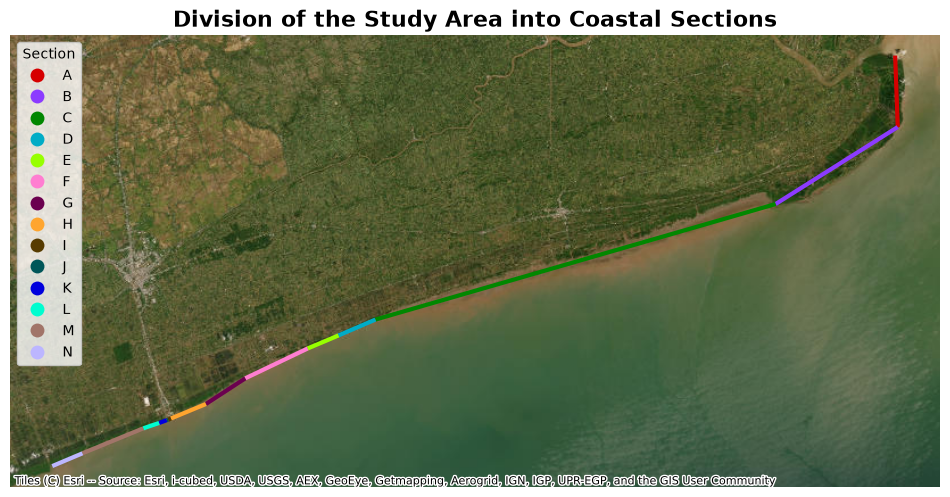

In [38]:
section_lines = plot_sections_map(sections)

## Historical Shoreline Analysis - Deltares Method

This is the historical continuous shoreline data. However, this data seems to pick up on roads and fish ponds often, and is therefore not the most reliable measure for coastline determination. See reconstructed coastlines based on series data for an improved output. 

In [39]:
def plot_historical_shorelines(shorelines, years=None):

    if years is not None:
        data = shorelines[
            shorelines["year"].isin(years)
        ]
    else:
        data = shorelines

    fig, ax = plt.subplots(figsize=(10, 10))

    data.plot(
        ax=ax,
        column="year",
        cmap=cc.m_bmy,
        legend=True,
        legend_kwds={
            "label": "Year",
            "orientation": "vertical"
        },
        linewidth=1.5,
        alpha=0.8
    )

    ctx.add_basemap(
        ax,
        crs=data.crs.to_string(),
        source=ctx.providers.Esri.WorldImagery
    )

    ax.set_title("Historical Shorelines")
    ax.set_axis_off()

    plt.tight_layout()
    plt.show()

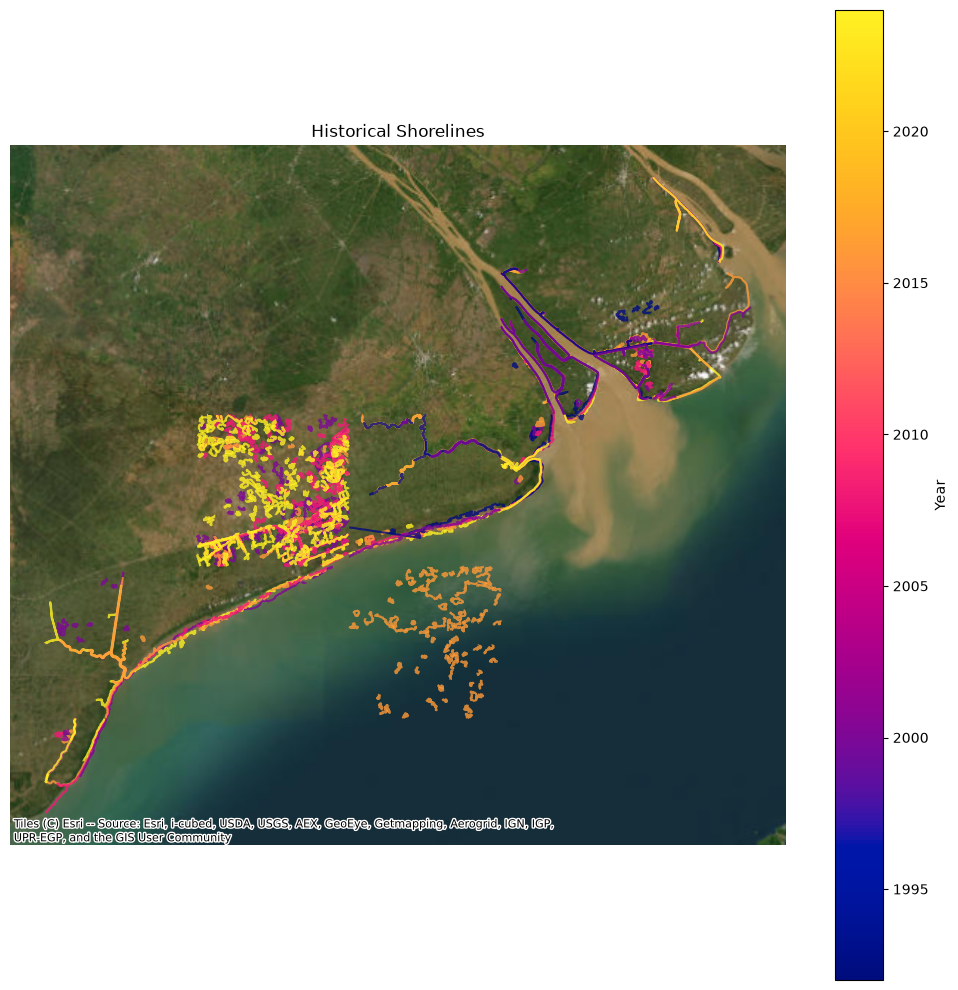

In [40]:
plot_historical_shorelines(
    shorelines,
    years=[1984, 1992, 2000, 2008, 2016, 2024]
)

## Figures per section: Shoreline Position and Change Rate

In [41]:
# Part 1 – Sections, transect locations and transect selection

UTM_EPSG = 32648   # metres, used for all distance calculations
MAP_EPSG = 3857    # Web Mercator, used for the satellite map


def section_title(section):
    names = selected_section_names(section)
    if len(names) == 1:
        return f"Section {names[0]}"
    return f"Sections {names[0]}–{names[-1]}"


def section_reference(section):
    names = selected_section_names(section)
    coords = [sections[names[0]][0]] + [sections[n][-1] for n in names]

    line_utm = gpd.GeoSeries(
        [LineString(coords)], crs="EPSG:4326"
    ).to_crs(UTM_EPSG).iloc[0]

    corners_utm = gpd.GeoSeries(
        [Point(c) for c in coords], crs="EPSG:4326"
    ).to_crs(UTM_EPSG)

    boundaries_km = [line_utm.project(p) / 1000 for p in corners_utm]

    return names, line_utm, boundaries_km


def runs_east_to_west(section):
    _, ref_utm, _ = section_reference(section)
    xs = [c[0] for c in ref_utm.coords]
    return xs[-1] < xs[0]


def transect_locations(series, change_rate):
    fixed = (
        change_rate[["transect_id", "lon", "lat"]]
        .dropna()
        .drop_duplicates("transect_id")
    )

    extra = (
        pd.DataFrame(series[["transect_id", "lon", "lat"]])
        .dropna()
        .loc[lambda d: ~d["transect_id"].isin(fixed["transect_id"])]
        .groupby("transect_id")[["lon", "lat"]]
        .median()
        .reset_index()
    )

    loc = pd.concat([fixed, extra], ignore_index=True)

    return gpd.GeoDataFrame(
        loc,
        geometry=gpd.points_from_xy(loc["lon"], loc["lat"]),
        crs="EPSG:4326",
    ).to_crs(UTM_EPSG)


def select_section_transects(section, locations, max_offset_m=1000):
    names, ref, bounds = section_reference(section)
    length_km = ref.length / 1000

    loc = locations.copy()
    loc["distance_km"] = loc.geometry.apply(ref.project) / 1000
    loc["offset_m"] = loc.geometry.distance(ref)

    inside = (
        (loc["distance_km"] > 0)
        & (loc["distance_km"] < length_km)
        & (loc["offset_m"] <= max_offset_m)
    )

    selected = loc.loc[inside, ["transect_id", "distance_km", "offset_m"]]
    selected = selected.sort_values("distance_km").reset_index(drop=True)

    print(
        f"{section_title(section)}: {len(selected)} transects selected "
        f"(~{length_km * 10:.0f} expected at 100 m spacing, "
        f"length {length_km:.2f} km)"
    )

    return selected




In [42]:

# Part 2 – Data: observations, outliers, shorelines, rates, rolling median

def primary_observations(series, transect_ids):
    """All primary observations for the given transects, one per transect-year."""
    obs = series[
        (series["obs_is_primary"] == True)
        & series["transect_id"].isin(transect_ids)
    ]

    obs = pd.DataFrame(obs.drop(columns="geometry", errors="ignore"))

    obs = (
        obs.dropna(subset=["lon", "lat", "shoreline_position", "year"])
        .drop_duplicates(["transect_id", "year"])
        .reset_index(drop=True)
    )

    return obs

def cross_shore_offset(obs, section):
    _, ref, _ = section_reference(section)

    pts = gpd.GeoSeries(
        gpd.points_from_xy(obs["lon"], obs["lat"]), crs="EPSG:4326"
    ).to_crs(UTM_EPSG)

    offsets = []
    for p in pts:
        d = ref.project(p)
        q = ref.interpolate(d)
        a = ref.interpolate(max(d - 1, 0))
        b = ref.interpolate(min(d + 1, ref.length))
        cross = (b.x - a.x) * (p.y - q.y) - (b.y - a.y) * (p.x - q.x)
        offsets.append(np.sign(cross) * p.distance(q))

    return np.asarray(offsets)

def flag_position_outliers(
    obs,
    transects,
    section,
    outlier_distance_m=300,
    window_years=4,
    min_neighbours=3,
    spike_distance_m=250,
    spike_neighbours=2,
    spike_max_gap_km=1.0,
):
    """
    Flag shoreline points that are probably tide / mudflat detections.
    Two independent checks; a point is an outlier if EITHER flags it:

    1. TEMPORAL – compared with the same transect in surrounding years:
       |position − median position within ±window_years| > outlier_distance_m
       (needs at least `min_neighbours` years in the window).
       Real long-term erosion/accretion is not flagged, because only nearby
       years are compared.

    2. SPATIAL (spikes) – compared with neighbouring points in the same
       year: the `spike_neighbours` nearest points on EACH side along the
       coast (at most spike_max_gap_km away). Flagged if
       |cross-shore offset − median offset of those neighbours| > spike_distance_m
       (needs ≥2 neighbours). This catches single points that stick out of
       the shoreline, also in sparse years and when a transect has too few
       years for the temporal check.
       Set spike_distance_m=None to switch this check off.
    """
    obs = obs.merge(transects[["transect_id", "distance_km"]], on="transect_id")
    obs["outlier_temporal"] = False
    obs["outlier_spike"] = False

    # 1. temporal check
    for _, g in obs.groupby("transect_id"):
        years = g["year"].to_numpy()
        pos = g["shoreline_position"].to_numpy()

        for idx, yr, p in zip(g.index, years, pos):
            near = np.abs(years - yr) <= window_years
            if near.sum() < min_neighbours:
                continue
            if abs(p - np.median(pos[near])) > outlier_distance_m:
                obs.at[idx, "outlier_temporal"] = True

    # 2. spatial spike check
    if spike_distance_m is not None:
        obs["offset_m"] = cross_shore_offset(obs, section)

        k = spike_neighbours

        for _, g in obs.groupby("year"):
            g = g.sort_values("distance_km")
            x = g["distance_km"].to_numpy()
            off = g["offset_m"].to_numpy()

            for j, idx in enumerate(g.index):
                nb = np.r_[max(j - k, 0):j, j + 1:min(j + k + 1, len(x))]
                nb = nb[np.abs(x[nb] - x[j]) <= spike_max_gap_km]
                if len(nb) < 2:
                    continue
                if abs(off[j] - np.median(off[nb])) > spike_distance_m:
                    obs.at[idx, "outlier_spike"] = True

    obs["outlier"] = obs["outlier_temporal"] | obs["outlier_spike"]

    return obs

def build_shorelines(obs, years):
    """ One connected shoreline per year, ordered along the coast by the fixed transect distance. """
    pts = obs[obs["year"].isin(years)].copy()

    pts = gpd.GeoDataFrame(
        pts,
        geometry=gpd.points_from_xy(pts["lon"], pts["lat"]),
        crs="EPSG:4326",
    ).to_crs(MAP_EPSG)

    lines = []

    for year in years:
        p = pts[(pts["year"] == year) & ~pts["outlier"]].sort_values("distance_km")

        if len(p) < 2:
            print(f"  {year}: fewer than 2 valid points – no shoreline drawn")
            continue

        lines.append({
            "year": year,
            "n_points": len(p),
            "geometry": LineString(p.geometry.tolist()),
        })

    if lines:
        lines = gpd.GeoDataFrame(lines, geometry="geometry", crs=MAP_EPSG)
    else:
        lines = gpd.GeoDataFrame(
            columns=["year", "n_points", "geometry"],
            geometry="geometry", crs=MAP_EPSG,
        )

    return lines, pts

def pairwise_slopes(years, positions):
    years = np.asarray(years, dtype=float)
    positions = np.asarray(positions, dtype=float)
    i, j = np.triu_indices(len(years), k=1)
    dx = years[j] - years[i]
    ok = dx != 0
    return (positions[j][ok] - positions[i][ok]) / dx[ok]

def theil_sen_rates(obs, transects, periods, min_obs=3, max_rate=200, pool_km=0.0):
    """
    Theil–Sen shoreline change rate (m/year) per transect and period.

    Uses all primary observations.
    Positive = seaward (accretion), negative = landward (erosion).

    min_obs : minimum number of observations (years) behind a rate.
    max_rate: rates beyond ±max_rate m/year are discarded.
    pool_km : 0   → every transect on its own (standard Theil–Sen).
              > 0 → pooled Theil–Sen: slopes between pairs of years are
                    computed WITHIN each transect (so every transect keeps its
                    own starting position) for the transect itself and its
                    neighbours within ±pool_km; the rate is the median of all
                    those slopes. With 100 m spacing:
                    pool_km=0.1 → 3 transects (~300 m of coast),
                    pool_km=0.2 → 5 transects (~500 m of coast).
                    The transect itself needs ≥2 years; min_obs then counts
                    all observations in the pool.
    """
    rows = []
    dist = transects.set_index("transect_id")["distance_km"]
    tolerance_km = 0.02   # absorbs small irregularities in transect spacing

    for start, end in periods:
        d = obs[(obs["year"] >= start) & (obs["year"] <= end)]
        groups = {tid: g for tid, g in d.groupby("transect_id")}

        for tid, g in groups.items():
            n_own = g["year"].nunique()

            if pool_km <= 0:
                # ---- single transect ----
                if n_own < min_obs:
                    continue
                slope, intercept, low, high = theilslopes(
                    g["shoreline_position"].to_numpy(),
                    g["year"].to_numpy(),
                )
                n_total, n_transects = n_own, 1

            else:
                # ---- pooled over neighbouring transects ----
                if n_own < 2:
                    continue

                members = [
                    t for t in groups
                    if abs(dist[t] - dist[tid]) <= pool_km + tolerance_km
                ]

                slopes, kendall_var, n_total, n_transects = [], 0.0, 0, 0
                for t in members:
                    gt = groups[t]
                    n = gt["year"].nunique()
                    if n < 2:
                        continue
                    slopes.append(pairwise_slopes(gt["year"], gt["shoreline_position"]))
                    kendall_var += n * (n - 1) * (2 * n + 5) / 18
                    n_total += n
                    n_transects += 1

                if n_total < min_obs:
                    continue

                slopes = np.sort(np.concatenate(slopes))
                slope = np.median(slopes)

                # 95% interval (same method as scipy's theilslopes, summed
                # over transects). Neighbouring transects are not fully
                # independent, so treat this interval as somewhat too narrow.
                c = 1.96 * np.sqrt(kendall_var)
                n_sl = len(slopes)
                low = slopes[max(int(np.round((n_sl - c) / 2)) - 1, 0)]
                high = slopes[min(int(np.round((n_sl + c) / 2)), n_sl - 1)]

                # Intercept for this transect's own observations
                intercept = np.median(
                    g["shoreline_position"].to_numpy() - slope * g["year"].to_numpy()
                )

            rows.append({
                "period": f"{start}–{end}",
                "start_year": start,
                "end_year": end,
                "transect_id": tid,
                "change_rate": slope,
                "intercept": intercept,
                "ci_low": low,
                "ci_high": high,
                "n_obs": n_total,
                "n_transects": n_transects,
            })

    rates = pd.DataFrame(rows, columns=[
        "period", "start_year", "end_year", "transect_id",
        "change_rate", "intercept", "ci_low", "ci_high", "n_obs", "n_transects",
    ])

    rates = rates[rates["change_rate"].abs() <= max_rate]

    rates = rates.merge(
        transects[["transect_id", "distance_km"]], on="transect_id"
    ).sort_values(["start_year", "distance_km"]).reset_index(drop=True)

    return rates

def rolling_median(x, y, window_km=1.0, min_points=3):
    """
    Rolling median along the coast: at every transect, the median rate of all
    transects within ±window_km/2. NaN where fewer than min_points are found.
    """
    x = np.asarray(x, dtype=float)
    y = np.asarray(y, dtype=float)
    out = np.full(len(x), np.nan)

    for i, xi in enumerate(x):
        inside = np.abs(x - xi) <= window_km / 2
        if inside.sum() >= min_points:
            out[i] = np.median(y[inside])

    return out

def intervention_rates(obs, transects, section, min_post_years=3, min_obs=3,
                       max_rate=200, pool_km=0.0):
    """ Rates for the period after each section's intervention was built """
    names, _, bounds = section_reference(section)
    end_year = int(series["year"].max())
    pieces, notes = [], {}

    for i, name in enumerate(names):
        iid = SECTION_INTERVENTIONS.get(name)
        if iid is None:
            continue
        built = BUILT[iid]

        if built > end_year:
            notes[name] = f"{iid} built {built}:\nno data after"
            continue
        if end_year - built + 1 < min_post_years:
            notes[name] = f"{iid} built {built}:\ntoo recent"
            continue

        r = theil_sen_rates(obs, transects, [(built, end_year)], min_obs, max_rate, pool_km)
        r = r[(r["distance_km"] >= bounds[i]) & (r["distance_km"] < bounds[i + 1])].copy()
        r["intervention"] = iid
        if r.empty:
            notes[name] = f"{iid}: too few\nobservations"
        pieces.append(r)

    columns = ["period", "start_year", "end_year", "transect_id", "change_rate",
               "intercept", "ci_low", "ci_high", "n_obs", "n_transects",
               "distance_km", "intervention"]
    post = pd.concat(pieces, ignore_index=True) if pieces else pd.DataFrame(columns=columns)
    return post, notes

In [43]:

# Part 3 – Plotting


ACCRETION_COLOURS = ["#8abee0", "#468cc8", "#1152aa"]   # pale → strong blue (newest)
EROSION_COLOURS = ["#f88e7a", "#dc4c48", "#a51314"]     # pale → strong red (newest)


def colour_ramp(cmap_name, n, light=0.40, dark=0.95):
    cmap = plt.get_cmap(cmap_name)
    if n == 1:
        return [cmap(dark)]
    return [cmap(v) for v in np.linspace(light, dark, n)]

def period_colours(palette, n):
    if n >= len(palette):
        return [palette[min(i, len(palette) - 1)] for i in range(n)]
    return palette[len(palette) - n:]


def latex_list(items):
    items = list(items)
    if len(items) <= 1:
        return "".join(items)
    return ", ".join(items[:-1]) + " and " + items[-1]

def plot_sign_coloured_line(ax, x, y, pos_colour, neg_colour,
                            linewidth=2.2, linestyle="-", zorder=4):
    x = np.asarray(x, dtype=float)
    y = np.asarray(y, dtype=float)
    if len(x) < 2:
        return

    xs, ys = [x[0]], [y[0]]
    for x0, y0, x1, y1 in zip(x[:-1], y[:-1], x[1:], y[1:]):
        if y0 * y1 < 0:
            xs.append(x0 + (x1 - x0) * (-y0) / (y1 - y0))
            ys.append(0.0)
        xs.append(x1)
        ys.append(y1)

    xs, ys = np.array(xs), np.array(ys)
    halo = [pe.Stroke(linewidth=linewidth + 1.6, foreground="white"), pe.Normal()]

    for colour, mask in [(pos_colour, ys >= 0), (neg_colour, ys <= 0)]:
        ax.plot(xs, np.where(mask, ys, np.nan), color=colour,
                linewidth=linewidth, linestyle=linestyle, zorder=zorder,
                solid_capstyle="round", path_effects=halo)

def map_extent(points, buffer_frac=0.08, min_buffer_m=150):
    xmin, ymin, xmax, ymax = points.total_bounds
    size = max(xmax - xmin, ymax - ymin)
    buffer = max(buffer_frac * size, min_buffer_m)
    return xmin - buffer, ymin - buffer, xmax + buffer, ymax + buffer

def plot_shoreline_panel(
    ax, shorelines, points, years, colours, section,
    show_points=True, label_sections=True,
    line_width=1.4, dot_gaps_m=None,
):
    halo = [pe.Stroke(linewidth=line_width + 1.0, foreground="black", alpha=0.35),
            pe.Normal()]

    for year, colour in zip(years, colours):
        line = shorelines[shorelines["year"] == year]
        n_pts = int(line["n_points"].iloc[0]) if not line.empty else 0

        if not line.empty:
            xy = np.asarray(line.geometry.iloc[0].coords)
            seg_len = np.hypot(*np.diff(xy, axis=0).T)
            gap = (seg_len > dot_gaps_m) if dot_gaps_m else np.zeros(len(seg_len), bool)

            solid = xy.astype(float).copy()
            x_s, y_s = [solid[0, 0]], [solid[0, 1]]
            for k in range(len(seg_len)):
                if gap[k]:
                    x_s.append(np.nan); y_s.append(np.nan)
                x_s.append(solid[k + 1, 0]); y_s.append(solid[k + 1, 1])
            ax.plot(x_s, y_s, color=colour, linewidth=line_width,
                    solid_joinstyle="round", zorder=4, path_effects=halo)

            for k in np.where(gap)[0]:
                ax.plot(xy[k:k + 2, 0], xy[k:k + 2, 1], color=colour,
                        linewidth=line_width, linestyle=":", zorder=4)

        year_pts = points[points["year"] == year]
        good = year_pts[~year_pts["outlier"]]
        bad = year_pts[year_pts["outlier"]]

        if show_points and not good.empty:
            ax.scatter(good.geometry.x, good.geometry.y, s=7, color=colour,
                       edgecolors="white", linewidths=0.3, zorder=5)
        if not bad.empty:
            ax.scatter(bad.geometry.x, bad.geometry.y, s=30, marker="x",
                       color=colour, linewidths=1.6, zorder=6,
                       path_effects=[pe.withStroke(linewidth=2.6, foreground="white")])

        ax.plot([], [], color=colour, linewidth=2.2, label=f"{year}  (n={n_pts})")

    if points["outlier"].any():
        ax.plot([], [], linestyle="none", marker="x", color="0.25",
                markersize=7, markeredgewidth=1.8, label="Outlier (not in line)")
    if dot_gaps_m:
        ax.plot([], [], color="0.25", linestyle=":", linewidth=1.6,
                label=f"Gap > {dot_gaps_m:g} m (connected)")

    names, ref_utm, _ = section_reference(section)
    ref_map = gpd.GeoSeries([ref_utm], crs=UTM_EPSG).to_crs(MAP_EPSG).iloc[0]
    corners = np.asarray(ref_map.coords)

    xmin, xmax = ax.get_xlim()
    ymin, ymax = ax.get_ylim()
    tick = 0.10 * min(xmax - xmin, ymax - ymin)

    latest = shorelines.sort_values("year").geometry.iloc[-1] if not shorelines.empty else None
    centres = []
    for c in corners:
        if latest is not None:
            snapped = nearest_points(latest, Point(c))[0]
            centres.append(np.array([snapped.x, snapped.y]))
        else:
            centres.append(c)
    centres = np.array(centres)

    start, end = corners[0], corners[-1]
    direction = (end - start) / np.linalg.norm(end - start)
    normal = np.array([-direction[1], direction[0]])
    pts_xy = np.column_stack([points.geometry.x, points.geometry.y])
    side = np.sign(np.median((pts_xy - centres.mean(axis=0)) @ normal)) or 1.0
    label_normal = -side * normal

    for i, centre in enumerate(centres):
        a = corners[max(i - 1, 0)]
        b = corners[min(i + 1, len(corners) - 1)]
        d = (b - a) / np.linalg.norm(b - a)
        n = np.array([-d[1], d[0]])
        p0, p1 = centre - n * tick / 2, centre + n * tick / 2
        ax.plot([p0[0], p1[0]], [p0[1], p1[1]], color="white",
                linestyle="--", linewidth=1.3, zorder=3)

    if label_sections:
        text_halo = [pe.withStroke(linewidth=2.5, foreground="black")]
        for i, name in enumerate(names):
            mid = (centres[i] + centres[i + 1]) / 2 + label_normal * tick * 0.8
            ax.text(mid[0], mid[1], name, color="white", fontsize=10,
                    fontweight="bold", ha="center", va="center", zorder=7,
                    path_effects=text_halo)

    ax.set_xlim(xmin, xmax)
    ax.set_ylim(ymin, ymax)
    ax.set_axis_off()
    ax.legend(title="Shoreline year", loc="best", fontsize=9, framealpha=0.85)
    ax.set_title(f"{section_title(section)} – Shorelines", fontsize=13)

STYLES = ["--", "-", ":"]                       
GRID_M, GRID_M_LONG, LONG_SECTOR_KM = 200, 1000, 8

def section_label(name):
    iid = SECTION_INTERVENTIONS.get(name)
    if iid is None:
        return name
    return f"{name}\n{iid} (built: {BUILT[iid]})"

def label_tiers(centres, span, min_gap_frac=0.09):
    last, tiers = {}, []
    for c in centres:
        t = 0
        while t in last and abs(c - last[t]) / span < min_gap_frac:
            t += 1
        last[t] = c
        tiers.append(t)
    return tiers

def draw_rate_series(ax, d, level, label, window_km, min_points, rate_ylim):
    d = d.sort_values("distance_km")
    blue, red, style = ACCRETION_COLOURS[level], EROSION_COLOURS[level], STYLES[level]

    x = d["distance_km"].to_numpy(dtype=float)
    y = d["change_rate"].to_numpy(dtype=float)
    colours = np.array([blue if v >= 0 else red for v in y])

    inside = np.ones(len(y), dtype=bool)
    if rate_ylim is not None:
        low, high = rate_ylim
        above, below = y > high, y < low
        inside = ~(above | below)
        for mask, edge, m in [(above, high, "^"), (below, low, "v")]:
            if mask.any():
                ax.scatter(x[mask], np.full(mask.sum(), edge), marker=m, s=40,
                           c=colours[mask], clip_on=False, zorder=5)

    ax.scatter(x[inside], y[inside], s=14, c=colours[inside], zorder=3)

    smooth = rolling_median(x, y, window_km, min_points)
    ok = np.isfinite(smooth)
    xs, ys = x[ok], smooth[ok]
    if len(xs) >= 2:
        lx, ly = [xs[0]], [ys[0]]
        for k in range(1, len(xs)):
            if ys[k - 1] * ys[k] < 0:
                lx.append(xs[k - 1] + (xs[k] - xs[k - 1]) * ys[k - 1] / (ys[k - 1] - ys[k]))
                ly.append(0.0)
            lx.append(xs[k])
            ly.append(ys[k])
        lx, ly = np.array(lx), np.array(ly)
        ax.plot(lx, np.where(ly >= 0, ly, np.nan), color=blue, linestyle=style, linewidth=2)
        ax.plot(lx, np.where(ly <= 0, ly, np.nan), color=red, linestyle=style, linewidth=2)

    handle = (Line2D([], [], color=blue, linestyle=style, linewidth=2),
              Line2D([], [], color=red, linestyle=style, linewidth=2))
    return handle, f"{label}  (n={len(d)})"


def plot_rate_panel(
    ax, rates, periods, section, window_km=1.0, min_points=3,
    label_sections=True, rate_ylim=None, match_map_direction=True,
    reliable_obs=5, reverse_x=None, post_rates=None, post_notes=None, pool_km=0.0,
):
    names, ref_utm, bounds = section_reference(section)
    length_km = ref_utm.length / 1000
    trans = blended_transform_factory(ax.transData, ax.transAxes)

    handles, labels = [], []
    n = len(periods)

    for i, (start, end) in enumerate(periods):
        d = rates[(rates["start_year"] == start) & (rates["end_year"] == end)]
        if d.empty:
            print(f"  {start}–{end}: no transects with enough observations")
            continue
        level = int(np.clip(i + (2 - n) if n <= 2 else i, 0, 2))
        h, l = draw_rate_series(ax, d, level, f"{start}–{end}", window_km, min_points, rate_ylim)
        handles.append(h)
        labels.append(l)

    if post_rates is not None and not post_rates.empty:
        starts = sorted(post_rates["start_year"].unique())
        end = int(post_rates["end_year"].max())
        span = f"{starts[0]}–{end}" if len(starts) == 1 else f"build year–{end}"
        h, l = draw_rate_series(ax, post_rates, 2, f"After intervention ({span})",
                                window_km, min_points, rate_ylim)
        handles.append(h)
        labels.append(l)

    ax.axhline(0, color="black", linewidth=0.8, zorder=2)

    if rate_ylim is not None:
        ax.set_ylim(*rate_ylim)

    # Background as in the intervention script
    y0, y1 = ax.get_ylim()
    ax.axhspan(0, max(y1, 0), color="#f2f7fc", zorder=0)
    ax.axhspan(min(y0, 0), 0, color="#fdf3f2", zorder=0)
    ax.set_ylim(y0, y1)

    # Dashed lines at internal section boundaries
    for b in bounds[1:-1]:
        ax.axvline(b, color="0.35", linestyle="--", linewidth=1.0, zorder=1)

    # Same left–right direction as the map
    if reverse_x is None:
        reverse_x = match_map_direction and runs_east_to_west(section)
    if reverse_x:
        ax.set_xlim(length_km, 0)
        ax.set_xlabel(f"Distance from start of Section {names[0]} (km)  ←")
    else:
        ax.set_xlim(0, length_km)
        ax.set_xlabel(f"Distance from start of Section {names[0]} (km)  →")

    # Grid as in the intervention script: minor lines every 200 m (1 km for long sections)
    grid_m = GRID_M if length_km <= LONG_SECTOR_KM else GRID_M_LONG
    ax.xaxis.set_minor_locator(MultipleLocator(grid_m / 1000))
    ax.grid(which="both", alpha=0.3)

    # Section letters + intervention (name, build year) above the panel
    max_tier = 0
    if label_sections:
        centres = [(bounds[i] + bounds[i + 1]) / 2 for i in range(len(names))]
        tiers = label_tiers(centres, length_km)
        max_tier = max(tiers)
        for name, c, t in zip(names, centres, tiers):
            ax.text(c, 1.01 + 0.075 * t, section_label(name), transform=trans,
                    ha="center", va="bottom", fontsize=9, fontweight="bold",
                    color="0.25", linespacing=1.1)

    ax.text(0.005, 0.98, "Accretion (seaward) ↑", transform=ax.transAxes,
            ha="left", va="top", fontsize=9, color=ACCRETION_COLOURS[2], fontweight="bold")
    ax.text(0.005, 0.02, "Erosion (landward) ↓", transform=ax.transAxes,
            ha="left", va="bottom", fontsize=9, color=EROSION_COLOURS[2], fontweight="bold")

    ax.set_ylabel("Change rate (m/year)")
    two_lines = label_sections and any(SECTION_INTERVENTIONS.get(nm) for nm in names)
    ax.set_title("Shoreline change rate", fontsize=13,
                 pad=(32 if two_lines else 20) + 24 * max_tier)

    if handles:
        ax.legend(handles, labels, title="Period",
                  handler_map={tuple: HandlerTuple(ndivide=None, pad=0.3)},
                  loc="upper right", fontsize=9, framealpha=0.9)

def coast_frame(section, transect_ids=None, match_map_direction=True): 
    """ Rotated map frame in which the coast runs horizontally:
        X = km along the section (same scale as the rate panel),
        Y = km across the coast, LAND UP and SEA DOWN.
    """
    _, ref_utm, _ = section_reference(section)
    ref_map = gpd.GeoSeries([ref_utm], crs=UTM_EPSG).to_crs(MAP_EPSG).iloc[0]
    corners = np.asarray(ref_map.coords)
    origin, end = corners[0], corners[-1]

    along = (end - origin) / np.linalg.norm(end - origin)
    across = np.array([-along[1], along[0]])

    flip = None
    if transect_ids is not None and isinstance(change_rate, gpd.GeoDataFrame):
        tr = change_rate[change_rate["transect_id"].isin(transect_ids)].to_crs(MAP_EPSG)
        vectors = []
        for g in tr.geometry:
            if g is None or g.geom_type != "LineString":
                continue
            c = np.asarray(g.coords)
            v = c[-1] - c[0]
            if np.linalg.norm(v) > 0:
                vectors.append(v / np.linalg.norm(v))
        if vectors:
            seaward = np.mean(vectors, axis=0)
            flip = -1.0 if seaward @ across > 0 else 1.0

    if flip is None:

        print("  Note: no transect lines found – map orientation from east/west rule.")
        flip = -1.0 if (match_map_direction and runs_east_to_west(section)) else 1.0

    lat = gpd.GeoSeries([Point(origin)], crs=MAP_EPSG).to_crs(4326).iloc[0].y
    scale = np.cos(np.radians(lat)) / 1000

    A = scale * np.array([along, flip * across])
    matrix = np.eye(3)
    matrix[:2, :2] = A
    matrix[:2, 2] = -A @ origin

    def to_frame(xy):
        xy = np.asarray(xy, dtype=float).reshape(-1, 2)
        return (xy - origin) @ A.T

    return to_frame, matrix, flip < 0

def frame_geometries(shorelines, points, to_frame):
    sl = gpd.GeoDataFrame(
        shorelines.drop(columns="geometry"),
        geometry=[LineString(to_frame(np.asarray(g.coords))) for g in shorelines.geometry],
    )
    xy = to_frame(np.column_stack([points.geometry.x, points.geometry.y]))
    pts = gpd.GeoDataFrame(
        points.drop(columns="geometry"),
        geometry=gpd.points_from_xy(xy[:, 0], xy[:, 1]),
    )
    return sl, pts


def add_rotated_basemap(ax, matrix, source=None):
    from matplotlib.transforms import Affine2D

    source = source or ctx.providers.Esri.WorldImagery
    xlim, ylim = ax.get_xlim(), ax.get_ylim()

    # Window corners (frame km) → Web Mercator, to know which tiles to fetch
    inv = np.linalg.inv(matrix)
    xs = [xlim[0], xlim[1], xlim[1], xlim[0]]
    ys = [ylim[0], ylim[0], ylim[1], ylim[1]]
    corners = (inv @ np.vstack([xs, ys, np.ones(4)]))[:2].T
    w, s = corners.min(axis=0)
    e, n = corners.max(axis=0)

    img, extent = ctx.bounds2img(w, s, e, n, zoom="auto", source=source, ll=False)

    im = ax.imshow(img, extent=extent, interpolation="bilinear", zorder=0)
    im.set_transform(Affine2D(matrix) + ax.transData)

    ax.set_xlim(xlim)
    ax.set_ylim(ylim)
    ctx.add_attribution(ax, source.get("attribution", ""), font_size=6)


def plot_rotated_shoreline_panel(
    ax, shorelines, points, years, colours, section,
    show_points=True, label_sections=True, line_width=1.4, dot_gaps_m=None,
    frame_matrix=None,
):
    halo = [pe.Stroke(linewidth=line_width + 1.0, foreground="black", alpha=0.35),
            pe.Normal()]
    gap_km = dot_gaps_m / 1000 if dot_gaps_m else None

    for year, colour in zip(years, colours):
        line = shorelines[shorelines["year"] == year]
        n_pts = int(line["n_points"].iloc[0]) if not line.empty else 0

        if not line.empty:
            xy = np.asarray(line.geometry.iloc[0].coords)
            seg_len = np.hypot(*np.diff(xy, axis=0).T)
            gap = (seg_len > gap_km) if gap_km else np.zeros(len(seg_len), bool)

            x_s, y_s = [xy[0, 0]], [xy[0, 1]]
            for k in range(len(seg_len)):
                if gap[k]:
                    x_s.append(np.nan); y_s.append(np.nan)
                x_s.append(xy[k + 1, 0]); y_s.append(xy[k + 1, 1])
            ax.plot(x_s, y_s, color=colour, linewidth=line_width,
                    solid_joinstyle="round", zorder=4, path_effects=halo)

            for k in np.where(gap)[0]:
                ax.plot(xy[k:k + 2, 0], xy[k:k + 2, 1], color=colour,
                        linewidth=line_width, linestyle=":", zorder=4)

        year_pts = points[points["year"] == year]
        good = year_pts[~year_pts["outlier"]]
        bad = year_pts[year_pts["outlier"]]

        if show_points and not good.empty:
            ax.scatter(good.geometry.x, good.geometry.y, s=7, color=colour,
                       edgecolors="white", linewidths=0.3, zorder=5)
        if not bad.empty:
            ax.scatter(bad.geometry.x, bad.geometry.y, s=30, marker="x",
                       color=colour, linewidths=1.6, zorder=6,
                       path_effects=[pe.withStroke(linewidth=2.6, foreground="white")])

        if n_pts > 0:   # years without a line are left out of the legend
            ax.plot([], [], color=colour, linewidth=2.2, label=f"{year}  (n={n_pts})")

    if points["outlier"].any():
        ax.plot([], [], linestyle="none", marker="x", color="0.25",
                markersize=7, markeredgewidth=1.8, label="Outlier (not in line)")
    if dot_gaps_m:
        ax.plot([], [], color="0.25", linestyle=":", linewidth=1.6,
                label=f"Gap > {dot_gaps_m:g} m (connected)")

    # Section boundaries: the same vertical dashed lines as in the rate panel
    names, _, bounds = section_reference(section)
    for b in bounds[1:-1]:
        ax.axvline(b, color="white", linestyle="--", linewidth=1.2, zorder=3)

    if label_sections:
        trans = blended_transform_factory(ax.transData, ax.transAxes)
        text_halo = [pe.withStroke(linewidth=2.5, foreground="black")]
        centres = [(bounds[i] + bounds[i + 1]) / 2 for i in range(len(names))]
        span = abs(ax.get_xlim()[1] - ax.get_xlim()[0])
        for name, c, t in zip(names, centres, label_tiers(centres, span)):
            ax.text(c, 0.96 - 0.14 * t, section_label(name), transform=trans,
                    color="white", fontsize=9, fontweight="bold", linespacing=1.1,
                    ha="center", va="top", zorder=7, path_effects=text_halo)

    # Axes like the mangrove figure: y in metres, x ticks without labels
    set_metre_ticks(ax)
    length_km = section_reference(section)[1].length / 1000
    grid_m = GRID_M if length_km <= LONG_SECTOR_KM else GRID_M_LONG
    ax.xaxis.set_minor_locator(MultipleLocator(grid_m / 1000))
    ax.tick_params(labelbottom=False)

    # Legend inside the map, lower left (just above the tile attribution);
    # one row when the map is low, one column when it is tall
    fig_h = ax.figure.get_size_inches()[1]
    tall = ax.get_position().height * fig_h >= 3
    n_entries = len(ax.get_legend_handles_labels()[0])
    if n_entries:
        ax.legend(loc="lower left", bbox_to_anchor=(0.005, 0.05),
                  ncol=1 if tall else n_entries, fontsize=8, framealpha=0.85,
                  handlelength=1.8, columnspacing=1.2)
    ax.set_title(f"Shoreline position ({section_title(section)})", fontsize=13)

def set_metre_ticks(ax):
    y0, y1 = ax.get_ylim()
    height_m = (y1 - y0) * 1000
    step = next((s for s in [50, 100, 200, 250, 500, 1000, 2000] if height_m / s <= 6), 5000)
    ticks_m = np.arange(0, height_m + 1e-6, step)
    ax.set_yticks(y1 - ticks_m / 1000)
    ax.set_yticklabels([f"{t:.0f}" for t in ticks_m])
    ax.set_ylabel("Distance (m)")

def print_rate_summary(rates, periods):
    print("\nChange-rate summary (Theil–Sen per transect)")
    for start, end in periods:
        d = rates[(rates["start_year"] == start) & (rates["end_year"] == end)]
        if d.empty:
            print(f"  {start}–{end}: no data")
            continue
        print(
            f"  {start}–{end}: {len(d):3d} transects | "
            f"median {d['change_rate'].median():6.2f} m/yr | "
            f"{(d['change_rate'] < 0).mean() * 100:4.0f}% eroding | "
            f"median n_obs {d['n_obs'].median():.0f}"
        )



In [44]:
# Part 4 – Main function to build the figure

def make_multisection_figure(
    section,
    shoreline_years,
    periods,
    *,
    min_obs=3,                 # min. years with data per transect for Theil–Sen
    pool_km=0.0,               # 0 = per transect; 0.1 = pool ±100 m (3 transects)  
    max_ci_width=None,         # e.g. 100: hide rates whose 95% CI is wider than this (m/yr) 
    reliable_obs=5,            # fewer years than this → open symbol
    max_rate=200,              # discard rates beyond ±max_rate m/year
    window_km=1.0,             # rolling-median window along the coast
    min_points=3,              # min. transects inside the window
    outlier_distance_m=300,    # temporal check: distance from neighbouring years
    outlier_window_years=4,    # "neighbouring years" = ±this many years
    spike_distance_m=250,      # spatial check: distance from neighbouring points (None = off)
    spike_neighbours=2,        # neighbours used on each side along the coast
    spike_max_gap_km=1.0,      # ... at most this far away
    max_offset_m=1000,         # max distance transect ↔ section reference line
    map_buffer_frac=0.08,      # empty space around the shorelines (fraction)
    min_buffer_m=150,          # ... but at least this many metres
    line_width=1.4,            # shoreline line width on the map
    dot_gaps_m=None,           # e.g. 300: draw gap-bridging pieces dotted (still connected)
    rate_ylim=None,            # e.g. (-60, 60); None = automatic
    match_map_direction=True,  # flip the rate panel so it runs like the map
    rotate_map=True,           # rotate the map so the coast is horizontal and lines up with the rates
    outlier_view_m=500,        # don't draw outliers further than this from the shoreline (None = draw all)
    show_outliers=False,       # True: draw outliers as × on the map
    post_intervention=True,    # add the period after each section's intervention was built
    min_post_years=3,          # ... only if at least this many years after construction
    fig_width=12,
    rate_panel_height=5.5,
    show_points=True,
    label_sections=True,
    basemap=True,
    save_path=None,            # e.g. "figures/sections_H_K.png"
    extra_top_m=0,             # extra space above the shorelines (land side), metres
    extra_bottom_m=0,          # extra space below the shorelines (sea side), metres
):
    shoreline_years = sorted(shoreline_years)       
    periods = sorted(periods, key=lambda p: (p[1], p[0]))

    if window_km == "auto":
        length_km = section_reference(section)[1].length / 1000
        window_km = float(np.clip(round(0.1 * length_km, 1), 0.3, 2.0))
        print(f"  Rolling-median window: {window_km:g} km (10% of section length)")

    locations = transect_locations(series, change_rate)
    transects = select_section_transects(section, locations, max_offset_m)

    obs = primary_observations(series, transects["transect_id"])

    obs = flag_position_outliers(
        obs, transects, section,
        outlier_distance_m, outlier_window_years,
        spike_distance_m=spike_distance_m, spike_neighbours=spike_neighbours,
        spike_max_gap_km=spike_max_gap_km,
    )

    shorelines, points = build_shorelines(obs, shoreline_years)
    rates = theil_sen_rates(obs, transects, periods, min_obs, max_rate, pool_km)

    rates["ci_width"] = rates["ci_high"] - rates["ci_low"]
    rates["plotted"] = True
    if max_ci_width is not None:
        rates["plotted"] = rates["ci_width"] <= max_ci_width
        for start, end in periods:
            p = rates[(rates["start_year"] == start) & (rates["end_year"] == end)]
            print(f"  {start}–{end}: {int((~p['plotted']).sum())} of {len(p)} rates hidden "
                  f"(95% CI wider than {max_ci_width:g} m/yr)")
    plot_rates = rates[rates["plotted"]]


    post_rates, post_notes = None, {}
    if post_intervention:
        post_rates, post_notes = intervention_rates(
            obs, transects, section, min_post_years, min_obs, max_rate, pool_km
        )
        if max_ci_width is not None and not post_rates.empty:
            keep = (post_rates["ci_high"] - post_rates["ci_low"]) <= max_ci_width
            print(f"  After intervention: {int((~keep).sum())} of {len(post_rates)} rates hidden "
                  f"(95% CI wider than {max_ci_width:g} m/yr)")
            post_rates = post_rates[keep]
        for name, note in post_notes.items():
            print(f"  Section {name}: {note.replace(chr(10), ' ')}")

    print(
        f"  Outliers in plotted years: {int(points['outlier'].sum())} of {len(points)} "
        f"points ({int(points['outlier_temporal'].sum())} temporal, "
        f"{int(points['outlier_spike'].sum())} spike)"
    )
    print_rate_summary(plot_rates, periods) 

    if points.empty:
        print("No shoreline points for the selected years – nothing to plot.")
        return None

    plot_points = points if show_outliers else points[~points["outlier"]]
    if plot_points.empty:             
        plot_points = points
    n_off_map = 0
    if outlier_view_m is not None and not shorelines.empty:
        from shapely.ops import unary_union
        cos_lat = np.cos(np.radians(points["lat"].mean()))   
        drawn = unary_union(list(shorelines.geometry))
        dist_m = plot_points.geometry.distance(drawn) * cos_lat
        far = plot_points.index[dist_m > outlier_view_m]
        n_off_map = len(far)
        if n_off_map:
            plot_points = plot_points.drop(index=far)
            print(f"  {n_off_map} point(s) more than {outlier_view_m:g} m from the "
                  f"shorelines not drawn on the map")

    reverse_x = None

    if rotate_map:
        to_frame, frame_matrix, reverse_x = coast_frame(
            section, transects["transect_id"], match_map_direction
        )
        shorelines_f, points_f = frame_geometries(shorelines, plot_points, to_frame)

        length_km = section_reference(section)[1].length / 1000
        y_lo, y_hi = points_f.geometry.y.min(), points_f.geometry.y.max()
        buffer_km = max(map_buffer_frac * (y_hi - y_lo), min_buffer_m / 1000)
        y_lo, y_hi = y_lo - buffer_km, y_hi + buffer_km
        y_lo -= extra_bottom_m / 1000
        y_hi += extra_top_m / 1000

        map_height = np.clip(1.3 * fig_width * (y_hi - y_lo) / length_km, 2.0, fig_width)
    else:
        xmin, ymin, xmax, ymax = map_extent(plot_points, map_buffer_frac, min_buffer_m)
        aspect = np.clip((xmax - xmin) / (ymax - ymin), 1.0, 3.0)
        map_height = fig_width / aspect

    fig, (ax1, ax2) = plt.subplots(
        2, 1,
        figsize=(fig_width, map_height + rate_panel_height + 0.9),
        gridspec_kw={"height_ratios": [map_height, rate_panel_height]},
    )

    plot_rate_panel(ax2, plot_rates, periods, section, window_km, min_points,
                    label_sections, rate_ylim, match_map_direction, reliable_obs,
                    reverse_x=reverse_x, post_rates=post_rates,
                    post_notes=post_notes, pool_km=pool_km)

    if rotate_map:
        ax1.set_xlim(*ax2.get_xlim())
        ax1.set_ylim(y_lo, y_hi)
        set_metre_ticks(ax1)
        ax1.tick_params(labelbottom=False)
        ax1.set_title(f"Shoreline position ({section_title(section)})", fontsize=13)
    else:
        ax1.set_axis_off()
        ax1.set_title(" ", pad=22)
    fig.tight_layout()


    fig_w, fig_h = fig.get_size_inches()
    box = ax1.get_position()
    box_ratio = (box.width * fig_w) / (box.height * fig_h)
    year_colours = colour_ramp("Purples", len(shoreline_years), light=0.45, dark=1.0)

    if rotate_map:
        x0, x1 = ax2.get_xlim()
        h = abs(x1 - x0) / box_ratio
        if h < (y_hi - y_lo):
            print("  Note: shorelines are wider across the coast than the map panel – "
                  "some may be cut off. Increase fig_width or shorten the section.")
        cy = (y_lo + y_hi) / 2

        ax1.set_xlim(x0, x1)
        ax1.set_ylim(cy - h / 2, cy + h / 2)
        ax1.set_aspect("equal")

        plot_rotated_shoreline_panel(ax1, shorelines_f, points_f, shoreline_years,
                                     year_colours, section, show_points,
                                     label_sections, line_width, dot_gaps_m, frame_matrix=frame_matrix)
        if basemap:
            add_rotated_basemap(ax1, frame_matrix)

    else:
        w, h = xmax - xmin, ymax - ymin
        cx, cy = (xmin + xmax) / 2, (ymin + ymax) / 2
        if w / h < box_ratio:
            w = h * box_ratio
        else:
            h = w / box_ratio

        ax1.set_xlim(cx - w / 2, cx + w / 2)
        ax1.set_ylim(cy - h / 2, cy + h / 2)
        ax1.set_aspect("equal")

        plot_shoreline_panel(ax1, shorelines, plot_points, shoreline_years, year_colours,
                             section, show_points, label_sections,
                             line_width, dot_gaps_m)

        if basemap:
            ctx.add_basemap(ax1, crs=f"EPSG:{MAP_EPSG}",
                            source=ctx.providers.Esri.WorldImagery,
                            attribution_size=6, reset_extent=True)

    if n_off_map:
        ax1.text(0.995, 0.015,
                                  f"{n_off_map} point(s) > {outlier_view_m:g} m from the shorelines not shown",
                 transform=ax1.transAxes, ha="right", va="bottom", fontsize=7,
                 color="white", path_effects=[pe.withStroke(linewidth=2, foreground="black")])

    if save_path is not None:
        Path(save_path).parent.mkdir(parents=True, exist_ok=True)
        fig.savefig(save_path, dpi=300, bbox_inches="tight")
        print(f"Saved: {save_path}")

    plt.show()

    return {
        "figure": fig,
        "transects": transects,
        "observations": obs,
        "points": points,
        "shorelines": shorelines,
        "rates": rates,
        "post_rates": post_rates,
    }

In [45]:

# Part 5 :Check one transect: positions through time + Theil–Sen fits
def plot_transect_series(result, distance_km=None, transect_id=None):
    """ Time series of one transect, to check what is behind a rate. """
    obs = result["observations"]
    rates = result["rates"]

    if transect_id is None:
        t = result["transects"]
        transect_id = t.loc[(t["distance_km"] - distance_km).abs().idxmin(), "transect_id"]

    g = obs[obs["transect_id"] == transect_id].sort_values("year")
    r = rates[rates["transect_id"] == transect_id]
    dist = g["distance_km"].iloc[0] if not g.empty else np.nan

    fig, ax = plt.subplots(figsize=(10, 4.5))

    ok = g[~g["outlier"]]
    bad = g[g["outlier"]]
    ax.plot(ok["year"], ok["shoreline_position"], "o", color="0.25",
            label="Primary observation")
    if not bad.empty:
        ax.plot(bad["year"], bad["shoreline_position"], "x", color="0.25",
                markersize=9, markeredgewidth=2,
                label="Flagged outlier (still used in rate)")

    n = len(r)
    blues = period_colours(ACCRETION_COLOURS, max(n, 1))
    reds = period_colours(EROSION_COLOURS, max(n, 1))

    for i, (_, row) in enumerate(r.sort_values("end_year").iterrows()):
        yrs = np.array([row["start_year"], row["end_year"]])
        colour = blues[i] if row["change_rate"] >= 0 else reds[i]
        ax.plot(yrs, row["intercept"] + row["change_rate"] * yrs, color=colour,
                linewidth=2.5,
                label=f"{row['period']}: {row['change_rate']:+.1f} m/yr "
                      f"(95% CI {row['ci_low']:+.1f} to {row['ci_high']:+.1f}, "
                      f"n={row['n_obs']})")

    ax.set_xlabel("Year")
    ax.set_ylabel("Shoreline position along transect (m)\n(higher = more seaward)")
    ax.set_title(f"Transect {transect_id}  –  {dist:.2f} km along section")
    ax.grid(True, linestyle=":", alpha=0.5)
    ax.legend(fontsize=9, loc="best")
    plt.tight_layout()
    plt.show()


Sections D–E: 49 transects selected (~49 expected at 100 m spacing, length 4.89 km)
  2020: fewer than 2 valid points – no shoreline drawn
  1990–2010: 2 of 49 rates hidden (95% CI wider than 100 m/yr)
  2010–2025: 0 of 45 rates hidden (95% CI wider than 100 m/yr)
  After intervention: 21 of 32 rates hidden (95% CI wider than 100 m/yr)
  Outliers in plotted years: 3 of 113 points (1 temporal, 2 spike)

Change-rate summary (Theil–Sen per transect)
  1990–2010:  47 transects | median -12.50 m/yr |   98% eroding | median n_obs 22
  2010–2025:  45 transects | median  -7.78 m/yr |   80% eroding | median n_obs 20


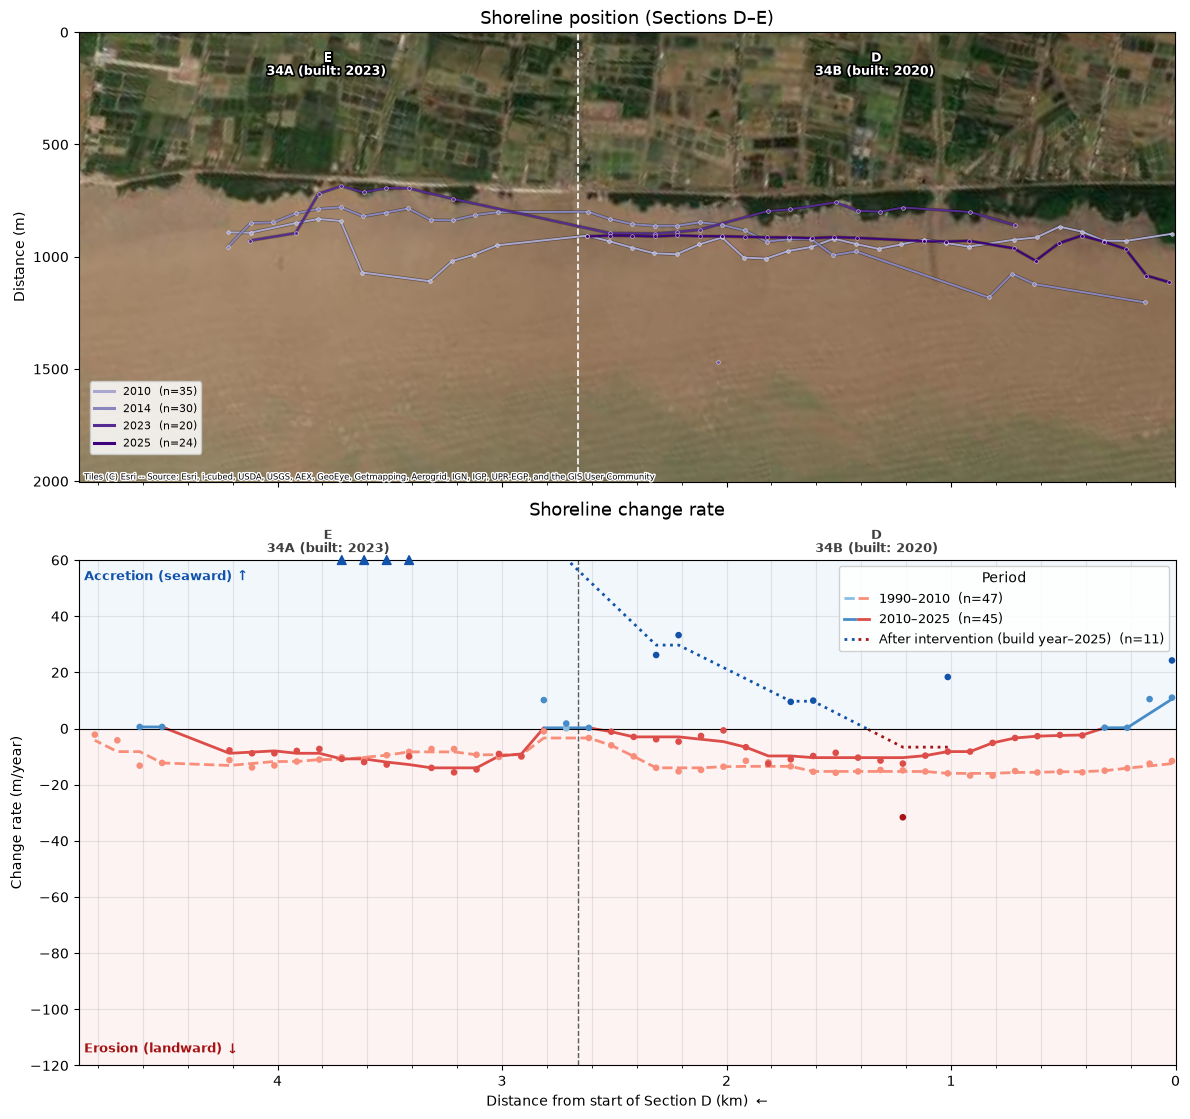

In [46]:
# Run Section Figure
# works for single or multiple sections, or entire coast (section=None)
section = ["D", "E"]

shoreline_years = [2010, 2014, 2020, 2023, 2025]

periods = [
    (1990, 2010),
    (2010, 2025),
]

result = make_multisection_figure(
    section,
    shoreline_years,
    periods,
    min_obs=3, #how many observations in a year needed before trusted
    min_points=2, #how many points needed to calculate the median rate
    window_km=0.5,
    pool_km=0.1,     # 0 = off, 0.1 = 3 transects (~300 m), 0.2 = 5 transects (~500 m)
    max_ci_width=100,   # None = off; lower = stricter
    rotate_map=True,    # False = normal north-up map
    rate_ylim=(-120, 60),
    map_buffer_frac=0.15,
    min_buffer_m=250,
    extra_top_m=200,
    extra_bottom_m=50,
)

name = "sections_" + "_".join(section) if section else "sections_all"
figures[name] = result["figure"]


## Full system erosion/accretion

In [47]:
OVERVIEW_GROUPS = ["A", "B", "C", "D", "E", "F", "G", ["H", "K"], "L", "M", "N"]

# Seven rate classes (m/year): erosion (red) → stable (white) → accretion (blue)
CLASS_EDGES = [-15, -5, -1, 1, 5, 15]
CLASS_COLOURS = ["#a51314", "#dc4c48", "#f88e7a", "#f2f2f2", "#8abee0", "#468cc8", "#1152aa"]
CLASS_CMAP = ListedColormap(CLASS_COLOURS)
CLASS_CMAP.set_under(CLASS_COLOURS[0])
CLASS_CMAP.set_over(CLASS_COLOURS[-1])
CLASS_NORM = BoundaryNorm([-30] + CLASS_EDGES + [30], CLASS_CMAP.N)
NO_DATA_COLOUR = "#bdbdbd"


def group_title(group):
    names = selected_section_names(group)
    return names[0] if len(names) == 1 else f"{names[0]}–{names[-1]}"

def along_coast_rates(periods, pool_km=0.1, min_obs=5, max_rate=200,
                      window_km=3.0, min_points=3, gap_km=2.0, max_offset_m=1000):

    all_names = list(SECTION_ORDER)
    whole = [all_names[0], all_names[-1]]

    locations = transect_locations(series, change_rate)
    transects = select_section_transects(whole, locations, max_offset_m)
    obs = primary_observations(series, transects["transect_id"])
    rates = theil_sen_rates(obs, transects, periods, min_obs, max_rate, pool_km)

    along = transects.sort_values("distance_km").reset_index(drop=True)
    dist = along["distance_km"].to_numpy(dtype=float)

    for start, end in periods:
        col = f"{start}–{end}"
        d = rates[(rates["start_year"] == start) & (rates["end_year"] == end)].sort_values("distance_km")
        x = d["distance_km"].to_numpy(dtype=float)
        y = rolling_median(x, d["change_rate"].to_numpy(dtype=float), window_km, min_points)
        ok = np.isfinite(y)
        if ok.sum() < 2:
            along[col] = np.nan
            continue
        values = np.interp(dist, x[ok], y[ok])
        nearest = np.min(np.abs(dist[:, None] - x[None, :]), axis=1)
        values[nearest > gap_km / 2] = np.nan
        along[col] = values
        print(f"  {col}: {len(d)} transect rates; "
              f"{np.isnan(values).mean():.0%} of the coast without data (gaps > {gap_km:g} km)")

    return whole, locations, along, rates

def draw_scale_bar(ax, length_km=10, lat=9.3):
    x0, x1 = ax.get_xlim()
    y0, y1 = ax.get_ylim()
    length = length_km * 1000 / np.cos(np.radians(lat))
    xs = x0 + 0.55 * (x1 - x0) - length
    ys = y0 + 0.07 * (y1 - y0)
    ax.plot([xs, xs + length], [ys, ys], color="black", linewidth=5, solid_capstyle="butt", zorder=9)
    ax.plot([xs, xs + length / 2], [ys, ys], color="white", linewidth=3, solid_capstyle="butt", zorder=10)
    ax.text(xs + length / 2, ys + 0.02 * (y1 - y0), f"{length_km:g} km", ha="center",
            va="bottom", fontsize=9, color="white", zorder=10,
            path_effects=[pe.withStroke(linewidth=2.5, foreground="black")])

def draw_band_map(ax, xy, values, extent, map_labels, corners, period_label,
                  band_width, basemap_source, darken, show_scale=True):
    xmin, xmax, ymin, ymax = extent
    ax.set_xlim(xmin, xmax)
    ax.set_ylim(ymin, ymax)
    ax.set_aspect("equal")

    segments = np.stack([xy[:-1], xy[1:]], axis=1)
    seg_values = (values[:-1] + values[1:]) / 2
    has = np.isfinite(seg_values)

    # soft glow under the band
    ax.add_collection(LineCollection(segments[has], colors="white", linewidths=band_width + 6,
                                     alpha=0.30, capstyle="round", joinstyle="round", zorder=4))
    band = LineCollection(segments[has], cmap=CLASS_CMAP, norm=CLASS_NORM,
                          linewidths=band_width, capstyle="round", joinstyle="round", zorder=5)
    band.set_array(seg_values[has])
    ax.add_collection(band)
    # stretches without data: thin grey dashed line
    if (~has).any():
        ax.add_collection(LineCollection(segments[~has], colors=NO_DATA_COLOUR,
                                         linewidths=2, linestyles=(0, (2, 2)), zorder=5))

    ax.scatter(corners[:, 0], corners[:, 1], s=30, marker="o", facecolor="white",
               edgecolor="black", linewidths=0.8, zorder=6)
    halo = [pe.withStroke(linewidth=3, foreground="black")]
    for text, mid, pos in map_labels:
        ax.annotate(text, xy=mid, xytext=pos, ha="center", va="center", fontsize=12,
                    fontweight="bold", color="white", zorder=7, path_effects=halo,
                    arrowprops=dict(arrowstyle="-", color="white", lw=0.9, alpha=0.8))

    ctx.add_basemap(ax, crs=f"EPSG:{MAP_EPSG}", source=basemap_source,
                    attribution_size=6, reset_extent=True)
    if darken:
        ax.add_patch(plt.Rectangle((0, 0), 1, 1, transform=ax.transAxes,
                                   color="black", alpha=darken, zorder=1))

    ax.text(0.02, 0.97, period_label, transform=ax.transAxes, ha="left", va="top",
            fontsize=22, color="white", zorder=9,
            path_effects=[pe.withStroke(linewidth=3, foreground="black")])
    ax.annotate("N", xy=(0.04, 0.80), xytext=(0.04, 0.69), xycoords="axes fraction",
                ha="center", va="center", fontsize=11, fontweight="bold", color="white",
                path_effects=[pe.withStroke(linewidth=2.5, foreground="black")],
                arrowprops=dict(arrowstyle="-|>", color="white", lw=2))
    if show_scale:
        draw_scale_bar(ax)
    ax.set_axis_off()
    return band

def make_overview_figure(
    period=(2010, 2025),
    groups=OVERVIEW_GROUPS,
    pool_km=0.1, min_obs=3,
    window_km=3.0,             # smoothing along the coast (overview = large pattern)
    min_points=3,
    gap_km=2.0,                # stretches without data longer than this stay grey
    band_width=8,              # width of the coloured band on the map (points)
    profile_ylim=(-30, 30),
    label_offset_km=3.0,       # how far seaward the section letters are placed on the map
    basemap_source=None,       # None = satellite (Esri World Imagery)
    darken=0.30,               # darken the satellite image so the band stands out (0 = off)
    show_profile=True,
    fig_width=14,
    save_path=None,
):
    col = f"{period[0]}–{period[1]}"
    if basemap_source is None:
        basemap_source = ctx.providers.Esri.WorldImagery

    whole, locations, along, rates = along_coast_rates(
        [tuple(period)], pool_km, min_obs, window_km=window_km,
        min_points=min_points, gap_km=gap_km)
    names, ref, bounds = section_reference(whole)
    length_km = ref.length / 1000
    reverse = runs_east_to_west(whole)

    extents = {}
    for g in groups:
        gn = selected_section_names(g)
        extents[group_title(g)] = (bounds[names.index(gn[0])], bounds[names.index(gn[-1]) + 1])

    pts = locations.set_index("transect_id").loc[along["transect_id"]].to_crs(MAP_EPSG)
    xy = np.column_stack([pts.geometry.x, pts.geometry.y])

    lines = change_rate[change_rate["transect_id"].isin(along["transect_id"])].to_crs(MAP_EPSG)
    group_mid = [sum(extents[group_title(g)]) / 2 for g in groups]
    label_level = label_tiers(group_mid, length_km, min_gap_frac=4 / length_km)
    map_labels = []
    for g, level in zip(groups, label_level):
        title = group_title(g)
        lo, hi = extents[title]
        mid_utm = ref.interpolate((lo + hi) / 2 * 1000)
        mid = np.asarray(gpd.GeoSeries([mid_utm], crs=UTM_EPSG).to_crs(MAP_EPSG).iloc[0].coords)[0]
        ids = along.loc[(along["distance_km"] >= lo) & (along["distance_km"] < hi), "transect_id"]
        vec = []
        for geom in lines[lines["transect_id"].isin(ids)].geometry:
            if geom is not None and geom.geom_type == "LineString":
                c = np.asarray(geom.coords)
                v = c[-1] - c[0]
                if np.linalg.norm(v) > 0:
                    vec.append(v / np.linalg.norm(v))
        sea = np.mean(vec, axis=0) if vec else np.array([0.0, -1.0])
        sea = sea / np.linalg.norm(sea)
        pos = mid + sea * label_offset_km * (1 + 0.8 * level) * 1000 / np.cos(np.radians(9.3))
        map_labels.append((title, mid, pos))

    ref_map = gpd.GeoSeries([ref], crs=UTM_EPSG).to_crs(MAP_EPSG).iloc[0]
    corners = np.asarray(ref_map.coords)

    all_xy = np.vstack([xy, np.array([p for _, _, p in map_labels])])
    xmin, ymin = all_xy.min(axis=0)
    xmax, ymax = all_xy.max(axis=0)
    pad = 0.05 * max(xmax - xmin, ymax - ymin)
    extent = (xmin - pad, xmax + pad, ymin - pad, ymax + pad)
    map_height = np.clip(fig_width * (extent[3] - extent[2]) / (extent[1] - extent[0]), 4, 9)

    heights = [map_height] + ([3.6] if show_profile else [])
    fig = plt.figure(figsize=(fig_width, sum(heights) + 1.4))
    gs = fig.add_gridspec(len(heights), 1, height_ratios=heights, hspace=0.12)
    ax_map = fig.add_subplot(gs[0])

    values = along[col].to_numpy(dtype=float)
    band = draw_band_map(ax_map, xy, values, extent, map_labels, corners, col,
                         band_width, basemap_source, darken, show_scale=True)

    cax = inset_axes(ax_map, width="34%", height="3%", loc="lower right", borderpad=5.5)
    cb = fig.colorbar(band, cax=cax, orientation="horizontal", spacing="uniform",
                      ticks=CLASS_EDGES)
    cb.ax.set_xticklabels([f"{e:g}" for e in CLASS_EDGES])
    cb.set_label("Shoreline change (m/year)", color="white", fontsize=11,
                 path_effects=[pe.withStroke(linewidth=2.5, foreground="black")])
    cb.ax.xaxis.set_label_position("top")
    cb.ax.tick_params(labelsize=9, colors="white")
    for t in cb.ax.get_xticklabels():
        t.set_path_effects([pe.withStroke(linewidth=2, foreground="black")])
    for x, txt, colour, ha in [(0.0, "Erosion", "#f88e7a", "left"),
                               (1.0, "Accretion", "#8abee0", "right")]:
        cax.text(x, -2.3, txt, transform=cax.transAxes, ha=ha, va="top", fontsize=9,
                 fontweight="bold", color=colour,
                 path_effects=[pe.withStroke(linewidth=2.5, foreground="black")])
    if np.isnan(values).any():
        cax.text(0.5, -2.3, "grey dashed: no data", transform=cax.transAxes, ha="center",
                 va="top", fontsize=8, color="white",
                 path_effects=[pe.withStroke(linewidth=2, foreground="black")])

    ax_map.set_title(f"Shoreline change {col} – Sections {names[0]}–{names[-1]}", fontsize=14)

    if show_profile:
        ax_prof = fig.add_subplot(gs[1])
        x = along["distance_km"].to_numpy(dtype=float)

        for k, g in enumerate(groups):
            lo, hi = extents[group_title(g)]
            if k % 2 == 0:
                ax_prof.axvspan(lo, hi, color="0.95", zorder=0)
            ax_prof.axvline(lo, color="0.7", linewidth=0.8, zorder=1)

        trans = blended_transform_factory(ax_prof.transData, ax_prof.transAxes)
        centres = [sum(extents[group_title(g)]) / 2 for g in groups]
        for g, c, t in zip(groups, centres, label_tiers(centres, length_km, 0.025)):
            ax_prof.text(c, 1.01 + 0.07 * t, group_title(g), transform=trans, ha="center",
                         va="bottom", fontsize=9, fontweight="bold", color="0.25")

        ax_prof.fill_between(x, 0, values, where=values >= 0, color=ACCRETION_COLOURS[1],
                             alpha=0.9, linewidth=0, interpolate=True, zorder=3)
        ax_prof.fill_between(x, 0, values, where=values <= 0, color=EROSION_COLOURS[1],
                             alpha=0.9, linewidth=0, interpolate=True, zorder=3)

        gap = np.isnan(values)
        if gap.any():
            edges = np.flatnonzero(np.diff(np.r_[0, gap.astype(int), 0]))
            for a, b in zip(edges[::2], edges[1::2]):
                ax_prof.axvspan(x[a], x[b - 1], facecolor="none", edgecolor="0.6",
                                hatch="///", linewidth=0, zorder=2)

        ax_prof.axhline(0, color="black", linewidth=0.9, zorder=4)
        ax_prof.set_ylim(*profile_ylim)
        ax_prof.set_xlim((length_km, 0) if reverse else (0, length_km))
        ax_prof.xaxis.set_minor_locator(MultipleLocator(1))
        ax_prof.grid(which="major", alpha=0.3)
        ax_prof.set_xlabel(f"Distance along the coast from the start of Section {names[0]} (km)"
                           + ("  ←" if reverse else "  →"))
        ax_prof.set_ylabel("Change rate (m/year)")
        ax_prof.text(0.005, 0.97, "Accretion ↑", transform=ax_prof.transAxes, ha="left",
                     va="top", fontsize=9, fontweight="bold", color=ACCRETION_COLOURS[2])
        ax_prof.text(0.005, 0.03, "Erosion ↓", transform=ax_prof.transAxes, ha="left",
                     va="bottom", fontsize=9, fontweight="bold", color=EROSION_COLOURS[2])
        if gap.any():
            ax_prof.legend([Patch(facecolor="none", edgecolor="0.6", hatch="///")],
                           ["no data"], loc="lower right", fontsize=9, framealpha=0.92)
        ax_prof.set_title(f"Change rate along the coast {col} ({window_km:g} km rolling median)",
                          fontsize=12, pad=24)

    if save_path is not None:
        Path(save_path).parent.mkdir(parents=True, exist_ok=True)
        fig.savefig(save_path, dpi=300, bbox_inches="tight")
        print(f"Saved: {save_path}")
    plt.show()

    return {"figure": fig, "along": along, "rates": rates}


Sections A–N: 662 transects selected (~654 expected at 100 m spacing, length 65.44 km)
  1988–2010: 542 transect rates; 0% of the coast without data (gaps > 2 km)


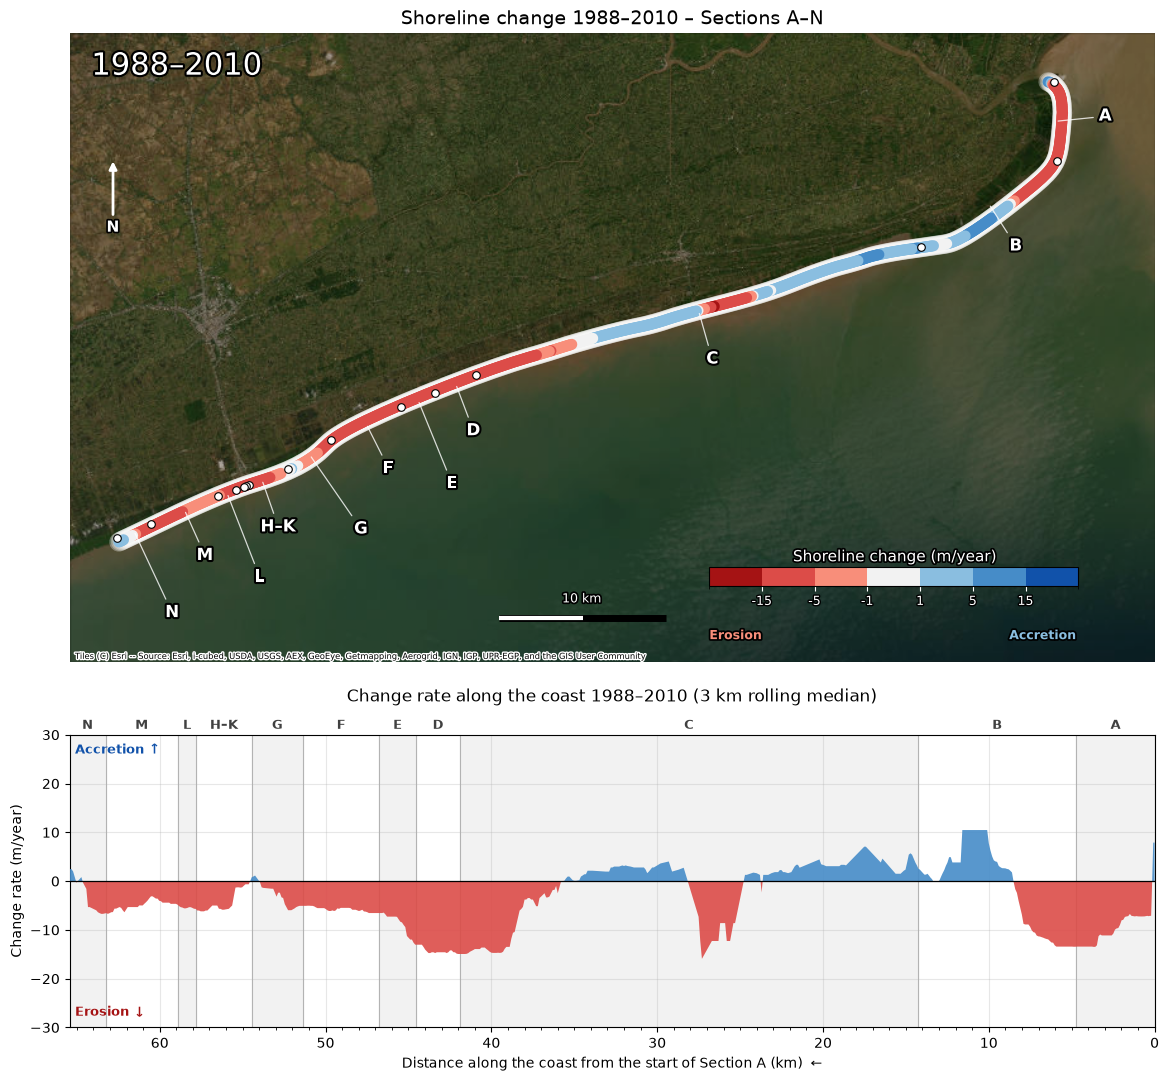

Sections A–N: 662 transects selected (~654 expected at 100 m spacing, length 65.44 km)
  2010–2025: 565 transect rates; 1% of the coast without data (gaps > 2 km)


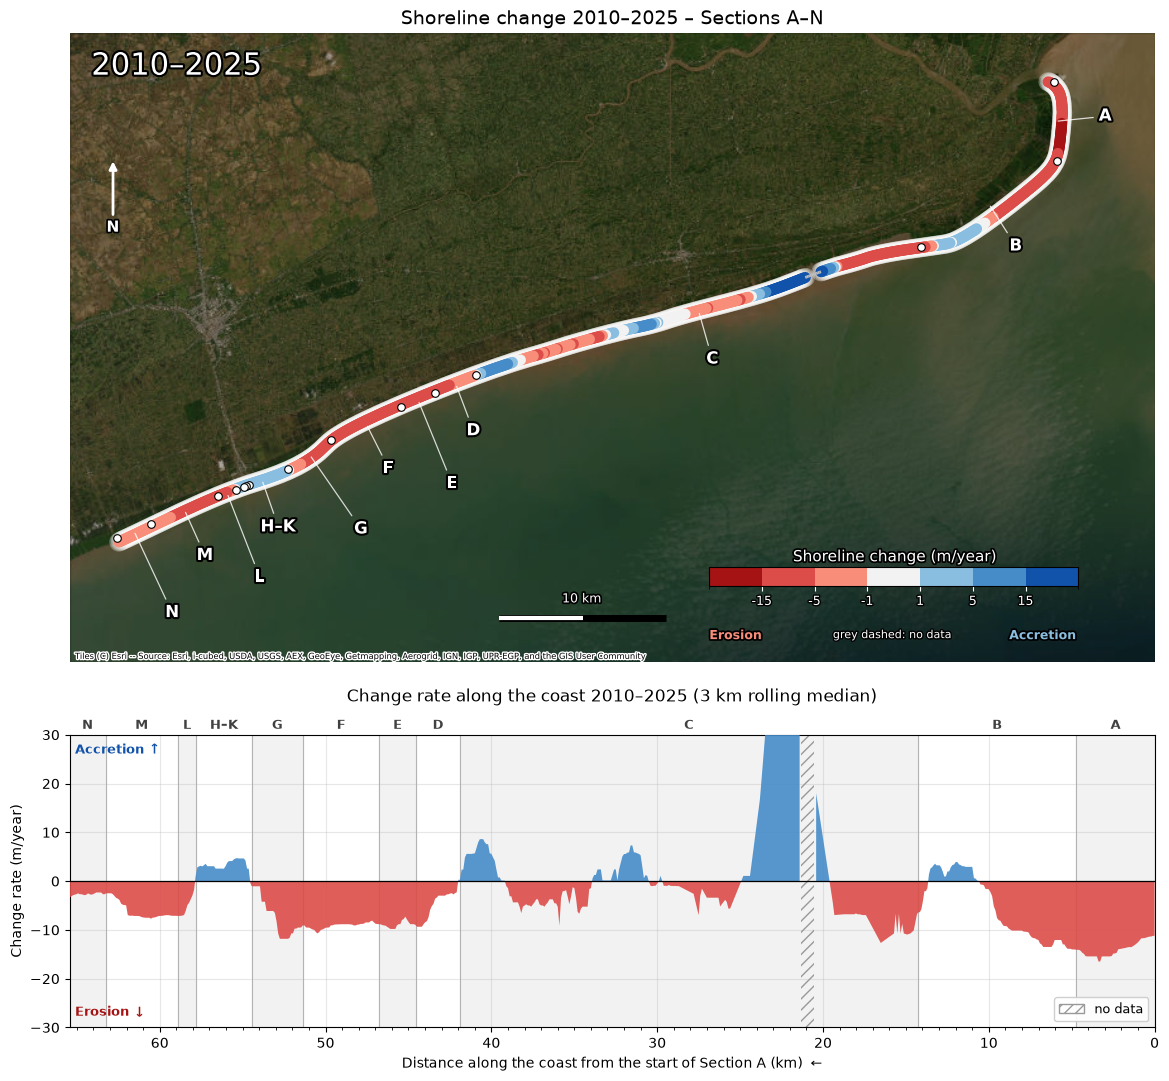

In [48]:
# Run Overview Figure
overview = {}
for period in [(1988, 2010), (2010, 2025)]:
    overview[period] = make_overview_figure(
        period=period,
        window_km=3.0,
        gap_km=2.0,
        profile_ylim=(-30, 30),     
    )

    figures[f"overview_{period[0]}_{period[1]}"] = overview[period]["figure"]

## Site specific analysis

In [49]:
def site_name(section, names):
    """Site label from a section or list of sections."""
    key = "".join(section) if isinstance(section, list) else section
    if key in names:
        return names[key]
    if isinstance(section, list):
        return f"Sections {section[0]}–{section[-1]}"
    return f"Section {section}"


def site_annual_positions(series, section, start_year=None, end_year=None,
                          max_change=500):
    """ One shoreline position per transect per year (primary observations only)."""
    data = select_sections(series, section).copy()
    data = data[data["obs_is_primary"]].dropna(
        subset=["datetime", "shoreline_position"]
    )
    if start_year is not None:
        data = data[data["year"] >= start_year]
    if end_year is not None:
        data = data[data["year"] <= end_year]

    # Remove gross outliers relative to each transect's median
    offset = (data["shoreline_position"]
              - data.groupby("transect_id")["shoreline_position"].transform("median"))
    data = data[offset.abs() <= max_change]

    return data.pivot_table(index="transect_id", columns="year",
                            values="shoreline_position", aggfunc="median")


def median_polish(table, n_iter=10):
    '''Split position = transect offset + year effect (Tukey's median polish).'''
   
    residual = table.copy()
    year_effect = pd.Series(0.0, index=table.columns)
    for _ in range(n_iter):
        row = residual.median(axis=1)
        residual = residual.sub(row, axis=0)
        col = residual.median(axis=0)
        residual = residual.sub(col, axis=1)
        year_effect += col
    return year_effect - year_effect.median()


def site_year_effect(table, min_transects=10, n_boot=200, seed=0):
    '''Year effect with bootstrap runs (resampling transects).'''
    
    n_obs = table.notna().sum(axis=0)
    table = table.loc[:, n_obs >= min_transects]

    effect = median_polish(table)

    rng = np.random.default_rng(seed)
    boot = []
    ids = table.index.to_numpy()
    for _ in range(n_boot):
        sample = table.loc[rng.choice(ids, size=len(ids), replace=True)]
        sample.index = range(len(sample))
        boot.append(median_polish(sample))
    boot = pd.DataFrame(boot)

    effect = pd.DataFrame({
        "effect": effect,
        "low": boot.quantile(0.05),
        "high": boot.quantile(0.95),
        "n_transects": n_obs[table.columns],
    })
    return effect, boot


def site_rates(effect, boot, table, periods, min_years=4, min_obs=5):
    ''' Rate per period = Theil–Sen slope of the site's yearly positions.'''
    
    rows = []
    years = effect.index.to_numpy(dtype=float)
    all_years = table.columns.to_numpy(dtype=float)

    for start, end in periods:
        sel = (years >= start) & (years <= end)
        row = {"start": start, "end": end, "n_years": int(sel.sum()),
               "rate": np.nan, "low": np.nan, "high": np.nan,
               "intercept": np.nan, "transect_rate": np.nan}

        if sel.sum() >= min_years:
            x = years[sel]
            slope, intercept, _, _ = stats.theilslopes(
                effect["effect"].to_numpy()[sel], x)
            boot_slopes = [
                stats.theilslopes(b[sel], x)[0]
                for b in boot.to_numpy() if np.isfinite(b[sel]).all()
            ]
            row.update(rate=slope, intercept=intercept,
                       low=np.percentile(boot_slopes, 5),
                       high=np.percentile(boot_slopes, 95))

        # Check: median of per-transect rates
        in_period = (all_years >= start) & (all_years <= end)
        slopes = []
        for _, values in table.loc[:, in_period].iterrows():
            ok = values.notna().to_numpy()
            if ok.sum() >= min_obs:
                slopes.append(stats.theilslopes(values.to_numpy()[ok],
                                                all_years[in_period][ok])[0])
        if slopes:
            row["transect_rate"] = np.median(slopes)

        rows.append(row)
    return pd.DataFrame(rows)


def plot_site_series(ax, effect, rates, colour, name, ylim=None):
    """One site: yearly position with band, plus a trend segment per period."""
    years = effect.index.to_numpy(dtype=float)

    ax.fill_between(years, effect["low"], effect["high"],
                    color=colour, alpha=0.18, lw=0, zorder=1)
    ax.plot(years, effect["effect"], color=colour, lw=1, alpha=0.6, zorder=2)
    ax.scatter(years, effect["effect"], s=18, color=colour,
               edgecolors="white", linewidths=0.6, zorder=3)

    for _, r in rates.iterrows():
        if np.isnan(r["rate"]):
            continue
        sel = (years >= r["start"]) & (years <= r["end"])
        xs = np.array([years[sel].min(), years[sel].max()])
        ys = r["intercept"] + r["rate"] * xs
        ax.plot(xs, ys, color="white", lw=5, zorder=4)
        ax.plot(xs, ys, color="0.15", lw=2.2, zorder=5)
        ax.annotate(f"{r['rate']:+.1f} m/yr  ({r['low']:+.1f} to {r['high']:+.1f})",
                    xy=(xs.mean(), ys.mean()), xytext=(0, 14),
                    textcoords="offset points", ha="center", va="bottom",
                    fontsize=9, color="0.15", zorder=6,
                    bbox=dict(boxstyle="round,pad=0.2", fc="white", ec="none",
                              alpha=0.85))

    for _, r in rates.iloc[1:].iterrows():
        ax.axvline(r["start"], color="0.5", lw=0.8, ls="--", zorder=0)

    ax.axhline(0, color="0.4", lw=0.7, zorder=0)
    ax.text(0.01, 0.95, name, transform=ax.transAxes, ha="left", va="top",
            fontsize=11, fontweight="bold", color=colour, zorder=7,
            bbox=dict(boxstyle="round,pad=0.25", fc="white", ec="none", alpha=0.9))
    ax.spines[["top", "right"]].set_visible(False)
    ax.grid(alpha=0.25)
    if ylim is not None:
        ax.set_ylim(ylim)


def plot_sites_through_time(series, groups, names=None, colours=None,
                            periods=((1988, 2010), (2010, 2023)),
                            start_year=None, end_year=None, max_change=500,
                            min_transects=10, min_years=4, min_obs=5, n_boot=200,
                            ylim=None, figsize=(11, 8), save_path=None):
    if names is None:
        names = {}
    if colours is None:
        colours = ["#E69F00", "#009E73", "#6A51A3", "#56B4E9", "#D55E00"]

    fig, axes = plt.subplots(len(groups), 1, figsize=figsize,
                             sharex=True, sharey=True)
    axes = np.atleast_1d(axes)

    summary = []
    for ax, section, colour in zip(axes, groups, colours):
        name = site_name(section, names)
        table = site_annual_positions(series, section, start_year, end_year,
                                      max_change)
        effect, boot = site_year_effect(table, min_transects, n_boot)
        rates = site_rates(effect, boot, table, periods, min_years, min_obs)
        plot_site_series(ax, effect, rates, colour, name, ylim)

        rates.insert(0, "site", name)
        rates.insert(1, "transects", len(table))
        summary.append(rates.drop(columns="intercept"))

    axes[len(axes) // 2].set_ylabel("Shoreline position relative to site median (m)")
    axes[-1].set_xlabel("Year")
    fig.suptitle("Shoreline position through time", y=0.995)
    fig.tight_layout()

    if save_path is not None:
        fig.savefig(save_path, dpi=300, bbox_inches="tight")
    plt.show()

    summary = pd.concat(summary, ignore_index=True)
    print(summary.round(2).to_string(index=False))
    return fig, summary


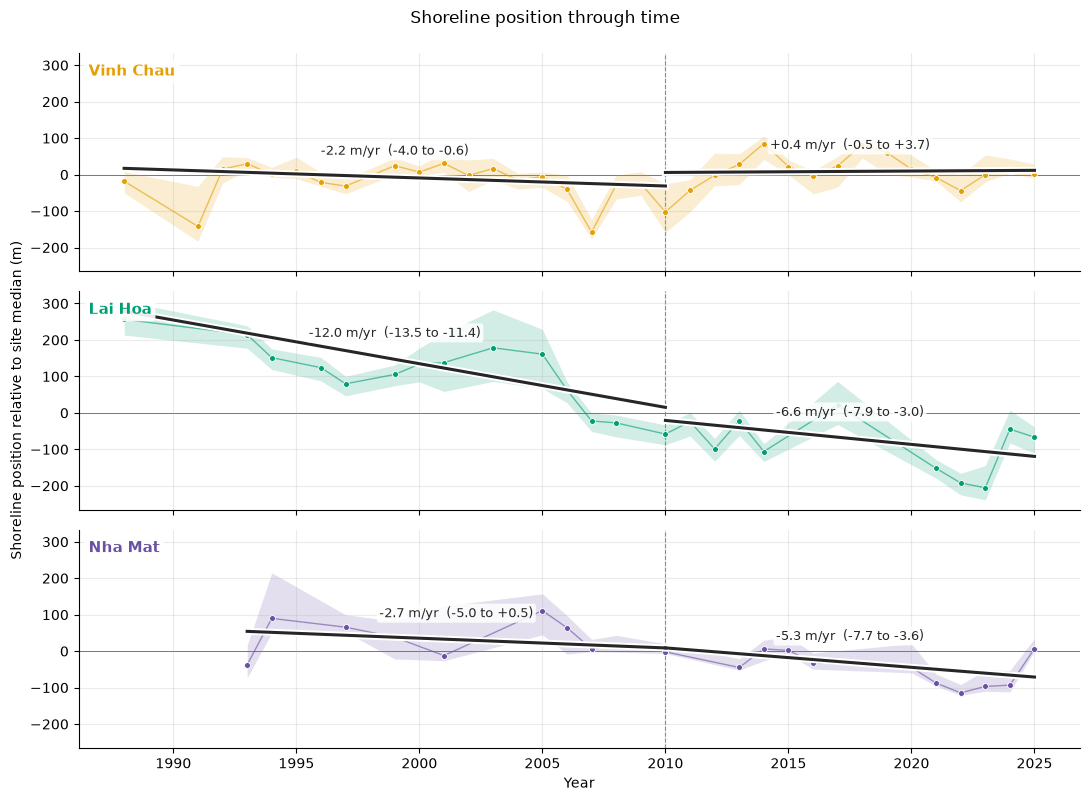

     site  transects  start  end  n_years   rate    low   high  transect_rate
Vinh Chau        269   1988 2010       20  -2.20  -3.97  -0.56          -3.86
Vinh Chau        269   2010 2025       16   0.39  -0.52   3.71           2.10
  Lai Hoa         50   1988 2010       14 -11.98 -13.50 -11.40         -13.96
  Lai Hoa         50   2010 2025       11  -6.58  -7.95  -2.98          -6.14
  Nha Mat         89   1988 2010       10  -2.67  -4.98   0.52          -6.74
  Nha Mat         89   2010 2025       11  -5.33  -7.66  -3.61          -6.61


In [50]:
# Run Site Rates

fig, site_summary = plot_sites_through_time(
    series,

    groups=["C", ["D", "E"], ["H", "M"]],
    names={"C": "Vinh Chau", "DE": "Lai Hoa", "HM": "Nha Mat"},
    colours=["#E69F00", "#009E73", "#6A51A3"],

    periods=[(1988, 2010), (2010, 2025)],   
    min_transects=10,  
    min_years=4,         
    min_obs=5,            
    max_change=500,       
    n_boot=200,
)

figures["site_rates"] = fig
tables["site_rates"] = site_summary.round(2)

## Table of change rate values (m/year) for each site and period

In [51]:
# Section shoreline change-rate table

def section_name(section):
    return f"{section[0]}–{section[-1]}" if isinstance(section, list) else section


def section_rate_table(groups, periods, min_obs=5, pool_km=0.1, max_ci_width=100,
                       max_rate=200, max_offset_m=1000, min_rates=5, min_coverage=0.5,
                       show_total=False):
    locations = transect_locations(series, change_rate)
    rows, coverage = [], []

    for section in groups:
        transects = select_section_transects(section, locations, max_offset_m)
        obs = primary_observations(series, transects["transect_id"])
        with contextlib.redirect_stdout(io.StringIO()):          
            rates = theil_sen_rates(obs, transects, periods, min_obs, max_rate, pool_km)
        if max_ci_width is not None:
            rates = rates[(rates["ci_high"] - rates["ci_low"]) <= max_ci_width]

        name = section_name(section)
        row, cov = {"Section": name}, {"Section": name}
        for start, end in periods:
            p = rates[(rates["start_year"] == start) & (rates["end_year"] == end)]
            share = len(p) / len(transects)
            enough = len(p) >= min_rates and share >= min_coverage
            row[f"{start}–{end}"] = p["change_rate"].median() if enough else np.nan
            cov[f"{start}–{end}"] = share

        if show_total:
            values = [(row[f"{s}–{e}"], e - s) for s, e in periods if pd.notna(row[f"{s}–{e}"])]
            row["Total"] = (sum(v * w for v, w in values) / sum(w for _, w in values)
                            if len(values) == len(periods) else np.nan)

        rows.append(row)
        coverage.append(cov)

    rates_table = pd.DataFrame(rows).set_index("Section").round(1)
    coverage_table = (pd.DataFrame(coverage).set_index("Section") * 100).round(0)
    return rates_table, coverage_table



In [52]:
# Run change rate table 
table_groups = ["A", "B", "C", ["D", "E"], "F", "G", ["H", "K"], "L", "M", "N"]
table_periods = [(1988, 2010), (2010, 2025)]

shore_rate, shore_coverage = section_rate_table(
    table_groups,
    table_periods,
    min_obs=5,         
    pool_km=0.1,        
    max_ci_width=100,    
    min_rates=5,        
    min_coverage=0.5,   
    show_total=False,
)
print("Share of transects with a rate (%):")
display(shore_coverage)

print("Shoreline change rate per section (m/year), positive = seaward:")
display(shore_rate)

tables["section_change_rates"] = shore_rate
tables["section_coverage"] = shore_coverage

Section A: 51 transects selected (~47 expected at 100 m spacing, length 4.71 km)
Section B: 99 transects selected (~96 expected at 100 m spacing, length 9.56 km)
Section C: 276 transects selected (~276 expected at 100 m spacing, length 27.61 km)
Sections D–E: 49 transects selected (~49 expected at 100 m spacing, length 4.89 km)
Section F: 46 transects selected (~46 expected at 100 m spacing, length 4.58 km)
Section G: 32 transects selected (~31 expected at 100 m spacing, length 3.11 km)
Sections H–K: 33 transects selected (~33 expected at 100 m spacing, length 3.35 km)
Section L: 11 transects selected (~11 expected at 100 m spacing, length 1.11 km)
Section M: 44 transects selected (~44 expected at 100 m spacing, length 4.36 km)
Section N: 22 transects selected (~22 expected at 100 m spacing, length 2.17 km)
Share of transects with a rate (%):


,1988–2010,2010–2025
Section,,
A,100.0,100.0
B,98.0,97.0
C,52.0,54.0
D–E,100.0,92.0
F,100.0,100.0
G,53.0,78.0
H–K,70.0,82.0
L,100.0,91.0
M,77.0,98.0


Shoreline change rate per section (m/year), positive = seaward:


,1988–2010,2010–2025
Section,,
A,-9.6,-13.8
B,-0.7,-7.5
C,-1.0,-1.3
D–E,-13.2,-7.8
F,-5.6,-9.1
G,-3.5,-8.2
H–K,-6.0,1.0
L,-5.8,3.8
M,-5.3,-7.1


In [55]:
# Save figures and tables (only when SAVE = True)
if SAVE:
    fig_dir.mkdir(parents=True, exist_ok=True)
    table_dir.mkdir(parents=True, exist_ok=True)
    for name, fig in figures.items():
        fig.savefig(fig_dir / f"{name}.png", dpi=300, bbox_inches="tight")
    for name, table in tables.items():
        table.to_csv(table_dir / f"{name}.csv", encoding="utf-8-sig")